# GMSC 실험 수행 기록

실행 목차

- 0. 필요한 모듈 불러오기
- 1. 데이터 로드
- 2. 데이터 분할 - stratify=y로 Train/Test 분리 및 Test 격리, 분할 인덱스 저장
- 3. Train 데이터 시각화 및 실험 기준 설정 - 주 지표 AP, threshold 목적 사전 설정
- 4. 결측치·왜도·특수값 확인/처리 - 유효한 위험 신호인지 확인 후 처리 후보 비교 - cv 내 구성
- 5. 모델 비교 및 AP/AUROC 기반 최적 모델 선발
- 6. 피처 표현 비교: Original(9개) / PCA(8개)
- 7. 선정 모델의 불균형 보정 비교
- 8. 보정 없는 XGB 튜닝 및 OOF threshold 선택
- 9. 설정 고정 후 최종 Test 평가
- 10. 마지막 추가 튜닝 및 발표자료
- 11. 기준 6개 모델과 튜닝 XGB의 Test Recall 비교
- 12. 최종 모델 joblib 내보내기
- 13. 외부 benchmark 모델 참고 비교
- 14. 최종 모델 TreeSHAP XAI 분석

최종 모델은 고정했다. 이후 비교·진단·신뢰구간은 사후 보완 분석으로 구분한다.


## 0. 필요한 모듈 불러오기

In [2]:
# 데이터 로드, 시각화
import joblib  # 최종 학습 파이프라인 저장·로드
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 분할, 교차검증, 튜닝
from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV
    )

# 전처리
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

# 특성 추출 및 결합
from sklearn.decomposition import PCA
from sklearn.pipeline import FeatureUnion

# 리샘플러 및 파이프라인 - SMOTE, NearMiss
from imblearn.over_sampling import SMOTE        # SMOTE (Over)
from imblearn.under_sampling import NearMiss    # NearMiss (Under)
from imblearn.pipeline import Pipeline

# 모델
from sklearn.linear_model\
    import LogisticRegression       # LR
from sklearn.tree\
    import DecisionTreeClassifier   # DT
from sklearn.ensemble import (
    RandomForestClassifier,         # RF
    ExtraTreesClassifier,           # ET
)
from lightgbm import LGBMClassifier # LGB
from xgboost import XGBClassifier   # XGB

# 평가 지표
from sklearn.metrics import (
    average_precision_score,    # AP
    roc_auc_score,              # AUROC
    precision_recall_curve,     # PR
    f1_score,                   # F1
    fbeta_score,                # F-beta
    matthews_corrcoef,          # MCC
    precision_score,            # Precision
    recall_score,               # Recall
    brier_score_loss,           # Brier
)

# 평가 시각화
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
)
from sklearn.calibration import CalibrationDisplay

# 공통 설정
SEED = 33

## 1. 데이터 로드

In [3]:
data = pd.read_csv("givemesomecredit.csv")

short_names = {
    'SeriousDlqin2yrs': 'Dlq2yrs',
    'RevolvingUtilizationOfUnsecuredLines': 'RevUtil',
    'age': 'Age',
    'NumberOfTime30-59DaysPastDueNotWorse': 'PastDue_30-59',
    'DebtRatio': 'DebtRatio',
    'MonthlyIncome': 'Income',
    'NumberOfDependents': 'Dependents',
    'CombinedDefaulted': 'CombDefault',
    'CombinedCreditLoans': 'CombCredit'
}

TARGET = "Dlq2yrs"

data = data.rename(columns=short_names)

X = data.drop(columns=[TARGET])
y = data[TARGET]

data.head(5)

,Dlq2yrs,RevUtil,Age,PastDue_30-59,DebtRatio,Income,Dependents,CombDefault,CombCredit
0,1,0.766127,45,2,0.802982,9120,2,1,1
1,0,0.957151,40,0,0.121876,2600,1,0,0
2,0,0.658180,38,1,0.085113,3042,0,1,0
3,0,0.233810,30,0,0.036050,3300,0,0,0
4,0,0.907239,49,1,0.024926,63588,0,1,1


- <b>[Target]</b>
    - Dlq2yrs: 신청자가 90일 이상의 연체(채무불이행) 또는 그보다 심각한 상황을 경험했는지 여부 - N (연체 없음 = 0) / Y (연체 있음 = 1) - 이진 범주형
- <b>[Feature]</b>
    - RevUtil: 신용카드 및 개인 신용한도(마이너스 통장 등)의 총 잔액 비율(한도 소진율) - 백분율 (연속형)
    - Age: 신청자 연령(세) - 정수형
    - PastDue_30-59: 최근 2년 간 30~59일 연체 발생 횟수 - 정수형
    - DebtRatio: 월간 총소득 대비 월간 부채 상환액, 위자료, 생활비의 비율(부채비율) - 수치형
    - Income: 월 소득 - 실수형
    - Dependents: 본인 제외 부양가족 수 - 범주형
    - CombDefault: 30~89일 또는 90일 이상 연체한 횟수 - 범주형
    - CombCredit: 부동산 담보 대출 및 주택자산 신용한도(HELOC)를 포함한 개설된 대출 및 신용한도의 총 개수 - 범주형

## 2. 데이터 분할 - stratify=y로 Train/Test 분리 및 Test 격리, 분할 인덱스 저장

In [4]:
TEST_SIZE = 0.2

X_train, X_test, y_train, y_test = train_test_split (
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=SEED,
)

np.savez(
    "split_indices.npz",
    train_idx = X_train.index.to_numpy(),
    test_idx = X_test.index.to_numpy(),
)

## 3. Train 데이터 시각화 및 실험 기준 설정 - 주 지표 AP, threshold 목적 사전 설정

In [5]:
# Feature - 기초통계, 왜도, 결측치 확인
overview = pd.concat (
    [
        X_train.describe().T,
        X_train.skew().rename("skew"),
        X_train.isnull().sum().rename("isnull")
    ],
    axis=1
    )
overview

,count,mean,std,min,25%,50%,75%,max,skew,isnull
RevUtil,120000.0,6.008512,249.011519,0.0,0.029851,0.154467,0.559169,50708.0,103.498422,0
Age,120000.0,52.328342,14.789786,21.0,41.000000,52.000000,63.000000,109.0,0.189488,0
PastDue_30-59,120000.0,0.413508,4.104862,0.0,0.000000,0.000000,0.000000,98.0,23.056155,0
DebtRatio,120000.0,356.018387,2206.085343,0.0,0.174629,0.366719,0.870754,329664.0,93.458696,0
Income,120000.0,6670.639008,12779.028666,0.0,3900.000000,6600.000000,7379.000000,3008750.0,136.857663,0
Dependents,120000.0,0.736475,1.105007,0.0,0.000000,0.000000,1.000000,20.0,1.618072,0
CombDefault,120000.0,0.202083,0.401556,0.0,0.000000,0.000000,0.000000,1.0,1.483837,0
CombCredit,120000.0,0.741283,0.437931,0.0,0.000000,1.000000,1.000000,1.0,-1.101941,0


결측치는 관측되지 않는다. RevUtil·DebtRatio·Income은 강한 왜도를 보이며, PastDue_30-59의 왜도도 약 23으로 크다. 특수값이 예측 신호일 수 있어 단순 삭제 전에 Train의 구간별 연체율을 확인한다.

In [6]:
# 연체 특수값 빈도
print(X_train["PastDue_30-59"].value_counts().sort_index())
print("96, 98에 대한 처리 필요")

# 로그 변환 대상의 범위·극단값 확인
log_cols = ["RevUtil", "DebtRatio", "Income"]

X_train[log_cols].quantile(
    [0, 0.5, 0.95, 0.99, 0.999, 1]
).T

PastDue_30-59
0     100831
1      12813
2       3702
3       1382
4        589
5        284
6        112
7         43
8         23
9         10
10         3
12         1
13         1
96         4
98       202
Name: count, dtype: int64
96, 98에 대한 처리 필요


,0.000,0.500,0.950,0.990,0.999,1.000
RevUtil,0.0,0.154467,1.00,1.091738,1620.009,50708.0
DebtRatio,0.0,0.366719,2451.05,4993.000000,10613.074,329664.0
Income,0.0,6600.000000,13500.00,23333.000000,71950.050,3008750.0


In [7]:
# Target - 클래스 불균형 확인
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
ir = round((neg/pos), 4)
print(f"IR = {ir}")

IR = 13.9607


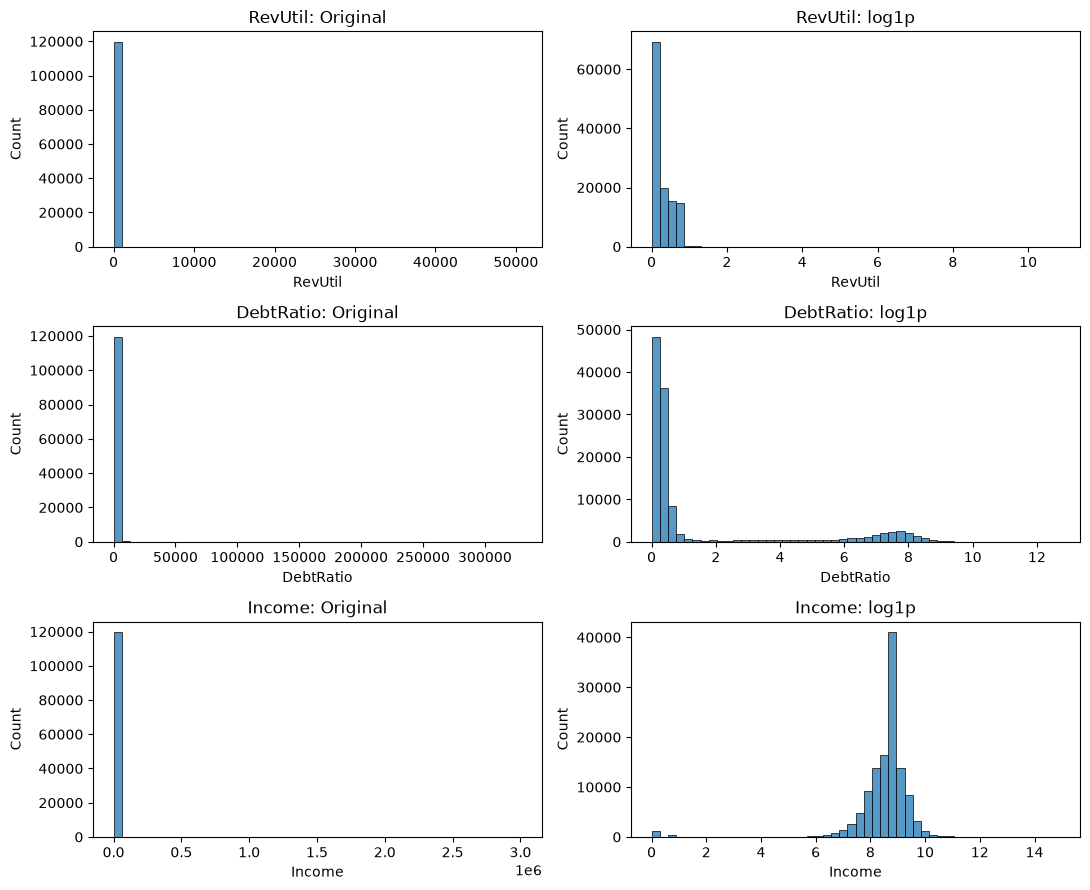

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9))

for i, col in enumerate(log_cols):
    sns.histplot(
        X_train[col], bins=50, ax=axes[i, 0]
    )
    sns.histplot(
        np.log1p(X_train[col]), bins=50, ax=axes[i, 1]
    )

    axes[i, 0].set_title(f"{col}: Original")
    axes[i, 1].set_title(f"{col}: log1p")

plt.tight_layout()
plt.show()

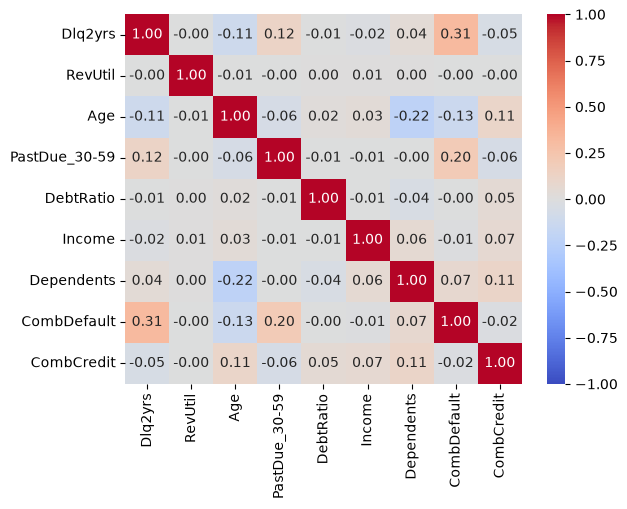

In [35]:
# Train의 정답·특성만 같은 행 인덱스로 결합한다. Test는 포함하지 않는다.
assert X_train.index.equals(y_train.index)
corr = pd.concat([y_train, X_train], axis=1).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

## 4. 결측치·왜도·특수값 확인/처리 - 유효한 위험 신호인지 확인 후 처리 후보 비교 - cv 내 구성

In [10]:
# 상세 구현과 주석은 gmsc_preprocessing.py에 보관한다.
# 모듈로 정의해야 joblib 파일을 새 Python 세션에서도 불러올 수 있다.
from gmsc_preprocessing import GMSCPreprocessor

### 4.1. Train 특수값·극단값 진단 및 전처리 ablation

- 아래는 최초 Test 확인 후의 보완 탐색이다. 최종 모델·임계값·기존 Test 결과는 변경하지 않았다.
- 96/98 및 재무 변수 구간의 실제 양성률·표본 수를 Train만으로 확인한다. 소표본 그룹은 변동성이 크다.
- DebtRatio 극단값이 전부 Income=0 때문이거나 달러 절대액이라고 단정하지 않는다. 가공·결측치 대체 전 기록은 제공되지 않았다.
- Income=0 그룹과 Income=6600 관측 그룹을 분리해 진단하되, 6600을 과거 결측치였다는 표식으로 간주하지 않는다.
- Raw8: 특수값·flag·로그 처리 없이 8개를 사용하되 스케일링은 공통 적용한다.
- Clean_NoLog: 특수값 치환+flag(9개). Clean_Log: 이에 로그 변환 추가. 두 조건 모두 fold 안에서 fit한다.
- Clean_Log_ZeroIncome: 로그 전에 관측 Income=0 flag를 추가한 탐색 조건(10개)이다.
- Raw8과 Clean_NoLog의 차이는 치환과 flag의 묶음 효과로, 각각의 단독 효과를 분리한 실험은 아니다.
- 기존 seed=33·5-fold, LR/XGB 초기 설정을 고정한다. 재현: `.\.venv\Scripts\python.exe supplementary_analysis.py`.


In [ ]:
from IPython.display import Image, display

# 보완 스크립트에서 실행·저장한 Train 진단과 CV 결과를 표시한다.
train_group_risk = pd.read_csv("submission/supplementary/train_group_risk.csv")
preprocessing_ablation = pd.read_csv("submission/supplementary/preprocessing_ablation.csv")
display(train_group_risk)
display(preprocessing_ablation)
display(Image(filename="submission/supplementary/train_group_risk.png"))
display(Image(filename="submission/supplementary/preprocessing_ablation.png"))


### 4.2. 보완 결과 해석

- 특수값96/98: 206건 중113건 양성(54.85%). flag 보존의 진단적 근거지만 최종 성능 개선의 인과 증거는 아니다.
- LR의 Raw8 AP=0.2438, Clean_NoLog=0.2656, Clean_Log=0.2767로 개선됐다.
- XGB는 Raw8 AP=0.3507, Clean_Log=0.3498로 로그가 개선을 보이지 않았다. 모든 모델에 로그가 필요하다고 주장하지 않는다.
- Zero_Income_flag 추가 후 LR AP=0.2767, XGB AP=0.3498로 뚜렷한 이득이 관찰되지 않았다.
- 이 사후 진단으로 기존 최종 모델을 재선정하거나 Test 성적을 교체하지 않는다.


## 5. 모델 비교 및 AP/AUROC 기반 최적 모델 선발

In [11]:
# Model 및 Scoring 세트 구성 및 모델 테스트 폴드 구성
models = {
    # Logistic Regression
    "LR": LogisticRegression(
        max_iter=2000,
        random_state=SEED,
    ),
    # Decision Tree         
    "DT": DecisionTreeClassifier(
        random_state=SEED,
    ),
    # Random Forest
    "RF": RandomForestClassifier(
        n_estimators=100,
        random_state=SEED,
        n_jobs=1,
    ),
    # Extra Tree
    "ET": ExtraTreesClassifier(
        n_estimators=100,
        random_state=SEED,
        n_jobs=1,
    ),
    # LightGBM
    "LGB": LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=SEED,
        n_jobs=1,
        verbosity=-1,
    ),
    # eXtreme Gradient Boosting
    "XGB": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=1,
    ),
}

scoring = {
    "AP": "average_precision",
    "AUROC": "roc_auc"
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

cv_splits = list(cv.split(X_train, y_train))

In [12]:
# Model Test
summaty_rows, fold_rows = [], []

for name, model in models.items():
    print(f"{name} 평가 시작...", flush=True)

    pipe = Pipeline([
        ("clean", GMSCPreprocessor(use_log=True)),
        ("scale", StandardScaler()),
        ("model", clone(model)),
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        n_jobs=3,
        error_score="raise",
    )

    for i in range(len(cv_splits)):
        fold_rows.append({
            "model": name,
            "fold": i + 1,
            "AP": scores["test_AP"][i],
            "AUROC": scores["test_AUROC"][i],
            "fit_time_sec": scores["fit_time"][i],
        })

    summaty_rows.append({
        "model": name,
        "AP_mean": scores["test_AP"].mean(),
        "AP_std": scores["test_AP"].std(ddof=1),
        "AUROC_mean": scores["test_AUROC"].mean(),
        "AUROC_std": scores["test_AUROC"].std(ddof=1),
        "fit_time_mean_sec": scores["fit_time"].mean(),
    })

    results = pd.DataFrame(summaty_rows).sort_values(
        "AP_mean", ascending=False
    )
    results.to_csv("baseline_summary.csv", index=False)
    pd.DataFrame(fold_rows).to_csv("baseline_folds.csv", index=False)

    print(
        f"{name} 평가 완료: "
        f"AP = {scores['test_AP'].mean():.3f}, "
        f"AUROC = {scores['test_AUROC'].mean():.3f} ",
        flush=True,
    )

LR 평가 시작...
LR 평가 완료: AP = 0.277, AUROC = 0.823 
DT 평가 시작...
DT 평가 완료: AP = 0.111, AUROC = 0.599 
RF 평가 시작...
RF 평가 완료: AP = 0.300, AUROC = 0.825 
ET 평가 시작...
ET 평가 완료: AP = 0.272, AUROC = 0.811 
LGB 평가 시작...
LGB 평가 완료: AP = 0.341, AUROC = 0.851 
XGB 평가 시작...
XGB 평가 완료: AP = 0.350, AUROC = 0.855 


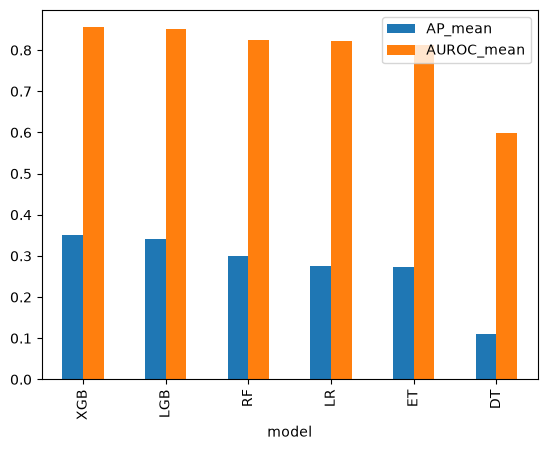

In [13]:
results.set_index("model")[["AP_mean", "AUROC_mean"]].plot(kind='bar')
plt.show()

Result =>  
- 1. XGB    -> 선별
- 2. LGB    -> 선별
- 3. RF     -> 선별
- 4. LR     -> 선별
- 5. ET
- 6. DT

In [14]:
selected_model = {}
selected_model["XGB"] = models["XGB"]
selected_model["LGB"] = models["LGB"]
selected_model["LR"] = models["LR"]
selected_model["RF"] = models["RF"]
print(selected_model.keys())

dict_keys(['XGB', 'LGB', 'LR', 'RF'])


## 6. 피처 표현 비교: Original(9개) / PCA(8개)

- 양쪽 모두 동일한 특수값 처리·로그 변환·스케일링을 적용하고 PCA 유무만 비교했다.
- DebtRatio × Income, 연체 강도 결합 등 도메인 파생변수 실험은 수행하지 않았다. 성능 개선이 없어서 제외했다는 의미가 아니다.
- 의미·단위가 확정되지 않은 변수의 계산을 피하고, Zero_Income_flag만 섹션 4의 보완 ablation에서 별도로 확인한다.
- 특성 선택기를 적용한 실험은 아니다. 최종 모델의 중요도·영향 방향은 뒤의 SHAP XAI에서 설명한다.


In [15]:
feature_options = {
    "Original": "passthrough",
    "PCA": PCA(n_components=0.95, svd_solver="full"),
}

feature_fold_rows = []

for model_name, base_model in selected_model.items():
    for feature_name, feature_step in feature_options.items():
        print(f"{model_name} / {feature_name} 평가 시작...", flush=True)

        model = clone(base_model)

        # 불균형 보정 없음
        if model_name in ("XGB", "LGB"):
            model.set_params(scale_pos_weight=1.0)
        if "class_weight" in model.get_params():
            model.set_params(class_weight=None)

        # PCA 조건별 객체 생성
        feature_transformer = (
            clone(feature_step)
            if feature_name == "PCA"
            else "passthrough"
        )

        pipe = Pipeline([
            ("clean", GMSCPreprocessor()),
            ("scale", StandardScaler()),
            ("feature", feature_transformer),
            ("model", model),
        ])

        # 기존 모델 비교와 같은 학습/분할
        scores = cross_validate(
            pipe,
            X_train,
            y_train,
            cv=cv_splits,
            scoring=scoring,
            return_estimator=True,
            n_jobs=3,
            error_score="raise",
        )

        for i, fitted_pipe in enumerate(scores["estimator"]):
            if feature_name == "PCA":
                n_features = (
                    fitted_pipe.named_steps["feature"].n_components_
                )
            else:
                n_features = (
                    fitted_pipe.named_steps["scale"].n_features_in_
                )

            feature_fold_rows.append({
                "model": model_name,
                "feature": feature_name,
                "fold": i + 1,
                "n_features": int(n_features),
                "AP": scores["test_AP"][i],
                "AUROC": scores["test_AUROC"][i],
                "fit_time_sec": scores["fit_time"][i],
            })

        # 조건 하나가 끝날 때마다 fold별 결과 저장
        pd.DataFrame(feature_fold_rows).to_csv(
            "feature_folds.csv", index=False
        )

        print(
            f"완료: AP={scores['test_AP'].mean():.4f}, "
            f"AUROC={scores['test_AUROC'].mean():.4f}",
            flush=True,
        )

XGB / Original 평가 시작...
완료: AP=0.3498, AUROC=0.8553
XGB / PCA 평가 시작...
완료: AP=0.3366, AUROC=0.8483
LGB / Original 평가 시작...
완료: AP=0.3405, AUROC=0.8510
LGB / PCA 평가 시작...
완료: AP=0.3318, AUROC=0.8456
LR / Original 평가 시작...
완료: AP=0.2767, AUROC=0.8228
LR / PCA 평가 시작...
완료: AP=0.2698, AUROC=0.8168
RF / Original 평가 시작...
완료: AP=0.2996, AUROC=0.8246
RF / PCA 평가 시작...
완료: AP=0.2892, AUROC=0.8190


In [16]:
feature_folds = pd.DataFrame(feature_fold_rows)

feature_summary = (
    feature_folds
    .groupby(["model", "feature"], sort=False)
    .agg(
        AP_mean=("AP", "mean"),
        AP_std=("AP", "std"),
        AUROC_mean=("AUROC", "mean"),
        AUROC_std=("AUROC", "std"),
        n_features_mean=("n_features", "mean"),
        fit_time_mean_sec=("fit_time_sec", "mean"),
    )
    .reset_index()
    .sort_values(
        ["model", "AP_mean"],
        ascending=[True, False],
        kind="stable",
    )
)

feature_summary.to_csv("feature_summary.csv", index=False)

display(feature_summary)

# 모델별로 AP가 높은 피처 조건 확인
best_feature_per_model = (
    feature_summary.groupby("model", sort=False).head(1)
)
display(best_feature_per_model)

,model,feature,AP_mean,AP_std,AUROC_mean,AUROC_std,n_features_mean,fit_time_mean_sec
2,LGB,Original,0.340543,0.010282,0.851041,0.003277,9.0,0.620297
3,LGB,PCA,0.331763,0.017104,0.845551,0.003033,8.0,0.687403
4,LR,Original,0.276665,0.007002,0.822787,0.002976,9.0,0.089942
5,LR,PCA,0.269846,0.006086,0.816834,0.002921,8.0,0.103751
6,RF,Original,0.299616,0.010842,0.824629,0.006010,9.0,11.070261
7,RF,PCA,0.289204,0.009448,0.819008,0.001221,8.0,21.992346
0,XGB,Original,0.349816,0.013607,0.855252,0.003205,9.0,0.592839
1,XGB,PCA,0.336567,0.015977,0.848265,0.002976,8.0,0.712134


,model,feature,AP_mean,AP_std,AUROC_mean,AUROC_std,n_features_mean,fit_time_mean_sec
2,LGB,Original,0.340543,0.010282,0.851041,0.003277,9.0,0.620297
4,LR,Original,0.276665,0.007002,0.822787,0.002976,9.0,0.089942
6,RF,Original,0.299616,0.010842,0.824629,0.006010,9.0,11.070261
0,XGB,Original,0.349816,0.013607,0.855252,0.003205,9.0,0.592839


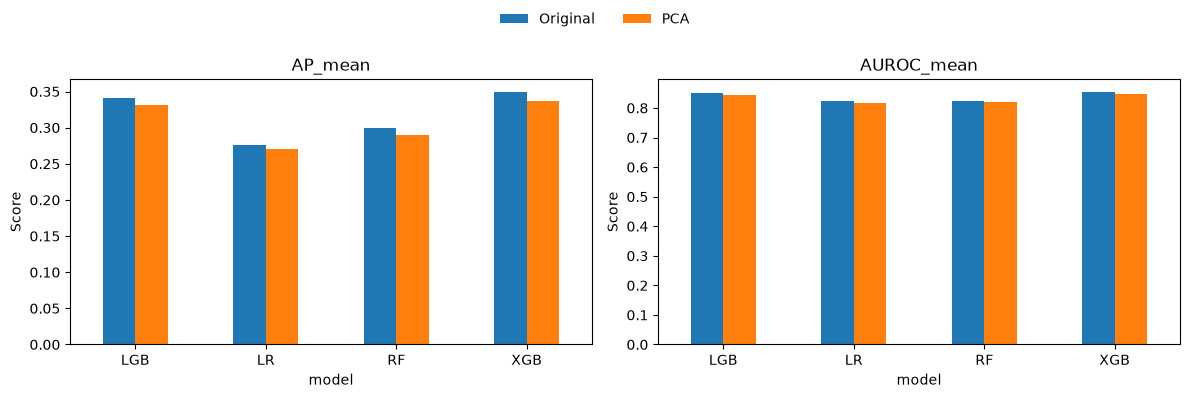

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["AP_mean", "AUROC_mean"]):
    feature_summary.pivot(
        index="model",
        columns="feature",
        values=metric,
    ).plot(kind="bar", ax=ax, rot=0)

    ax.set_title(metric)
    ax.set_ylabel("Score")
    ax.legend_.remove()

# 공통 범례를 그림 위쪽에 배치
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center",
    ncol=2,
    frameon=False,
)

plt.tight_layout(rect=[0, 0, 1, 0.90])  # 위쪽에 범례 공간 확보
plt.show()

## Result
PCA 적용 시 입력 차원은 9개에서 8개로 감소했으나, 비교한 4개 모델 전부 예측 성능은 하락했다. 제한적인 차원 축소에 비해 예측에 유용한 정보가 손실되었을 수 있고, 특히 트리 모델에서는 주성분 변환으로 원본 변수의 구조 활용이 어려워졌을 수 있다.

## 7. 선정 모델의 불균형 보정 비교

- PCA 비교 결과에 따라 Original(공통 전처리 후 9개 특성)을 사용한다.
- 선정 모델 4개 × 보정 조건 4개 × 기존 5-fold = 80회 학습한다.
- None / IR / SMOTE / NearMiss를 비교하며 가중치와 리샘플링은 동시에 적용하지 않는다.
- IR은 각 fold 학습 부분의 음성 수 / 양성 수로 계산한다.
- XGB/LGB는 scale_pos_weight, LR/RF는 class_weight={0: 1, 1: IR}를 사용한다.
- SMOTE/NearMiss는 우선 학습 클래스 수를 1:1로 맞춘다. 검증 데이터는 리샘플링하지 않는다.
- 일반 SMOTE는 횟수형·이진 flag도 연속값으로 보간한다는 한계가 있다.
- AP 평균으로 다음 튜닝 후보를 선택하고 AUROC는 보조로 본다. Test는 아직 사용하지 않는다.
- OOF 예측은 각 행을 학습에서 제외한 모델의 확률이다. 이후 설정을 튜닝하면 OOF도 다시 생성해야 한다.


In [18]:
from time import perf_counter

balance_methods = ["None", "IR", "SMOTE", "NearMiss"]
balance_fold_rows = []

# OOF를 원래 Train 행 순서로 저장한다. 원본 행 인덱스도 보존한다.
balance_oof = pd.DataFrame({
    "row_index": X_train.index.to_numpy(),
    "y_true": y_train.to_numpy(),
})
oof_fold = np.zeros(len(X_train), dtype=int)
for fold, (_, valid_idx) in enumerate(cv_splits, start=1):
    oof_fold[valid_idx] = fold
balance_oof["cv_fold"] = oof_fold

for model_name, base_model in selected_model.items():
    for method in balance_methods:
        print(f"{model_name} / {method} 평가 시작", flush=True)
        oof_prob = np.full(len(X_train), np.nan)
        valid_counts = np.zeros(len(X_train), dtype=int)

        for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
            # 분할 인덱스는 행 위치이므로 iloc을 사용한다.
            X_fit, y_fit = X_train.iloc[train_idx], y_train.iloc[train_idx]
            X_valid, y_valid = X_train.iloc[valid_idx], y_train.iloc[valid_idx]

            neg = int((y_fit == 0).sum())
            pos = int((y_fit == 1).sum())
            ir = neg / pos

            # 모델을 복제하고 기존 가중치가 다른 조건에 남지 않도록 초기화한다.
            model = clone(base_model)
            if "class_weight" in model.get_params():
                model.set_params(class_weight=None)
            if model_name in ("XGB", "LGB"):
                model.set_params(scale_pos_weight=1.0)

            if method == "IR":
                if model_name in ("XGB", "LGB"):
                    model.set_params(scale_pos_weight=ir)
                else:
                    model.set_params(class_weight={0: 1.0, 1: ir})

            sampler = "passthrough"
            if method == "SMOTE":
                sampler = SMOTE(sampling_strategy=1.0, random_state=SEED)
            elif method == "NearMiss":
                sampler = NearMiss(sampling_strategy=1.0, version=1)

            pipe = Pipeline([
                ("clean", GMSCPreprocessor(use_log=True)),
                ("scale", StandardScaler()),
                ("sampler", sampler),
                ("model", model),
            ])

            # 학습 부분만으로 전처리·리샘플링·모델 학습을 수행한다.
            start = perf_counter()
            pipe.fit(X_fit, y_fit)
            fit_seconds = perf_counter() - start

            # predict_proba에서는 sampler를 건너뛰므로 검증 행 수가 유지된다.
            positive_col = list(pipe.classes_).index(1)
            prob = pipe.predict_proba(X_valid)[:, positive_col]
            oof_prob[valid_idx] = prob
            valid_counts[valid_idx] += 1

            ap = average_precision_score(y_valid, prob)
            auroc = roc_auc_score(y_valid, prob)
            balance_fold_rows.append({
                "model": model_name,
                "balance": method,
                "fold": fold,
                "train_neg": neg,
                "train_pos": pos,
                "IR": ir,
                "positive_weight": ir if method == "IR" else 1.0,
                "AP": ap,
                "AUROC": auroc,
                "fit_time_sec": fit_seconds,
            })
            print(
                f"  fold {fold}/{len(cv_splits)}: "
                f"AP={ap:.4f}, AUROC={auroc:.4f}",
                flush=True,
            )

        # 모든 행이 한 번씩 검증됐고 유효한 확률을 얻었는지 확인한다.
        assert (valid_counts == 1).all(), "검증 행 중복 또는 누락"
        assert np.isfinite(oof_prob).all(), "OOF 확률에 결측 또는 무한대 존재"
        assert ((0 <= oof_prob) & (oof_prob <= 1)).all()
        balance_oof[f"{model_name}__{method}"] = oof_prob

        # 조건 하나가 끝날 때마다 저장해 완료된 결과를 남긴다.
        balance_folds = pd.DataFrame(balance_fold_rows)
        balance_summary = (
            balance_folds.groupby(["model", "balance"], sort=False)
            .agg(
                AP_mean=("AP", "mean"),
                AP_std=("AP", "std"),
                AUROC_mean=("AUROC", "mean"),
                AUROC_std=("AUROC", "std"),
                fit_time_mean_sec=("fit_time_sec", "mean"),
            )
            .reset_index()
            .sort_values("AP_mean", ascending=False, kind="stable")
        )
        balance_folds.to_csv("balance_folds.csv", index=False)
        balance_summary.to_csv("balance_summary.csv", index=False)
        balance_oof.to_csv("balance_oof.csv", index=False)

display(balance_summary)

# 다음 튜닝 대상 후보이며 최종 Test 성적이 아니다.
best_balance_config = balance_summary.iloc[0]
print("다음 튜닝 후보:")
print(best_balance_config[["model", "balance", "AP_mean", "AUROC_mean"]])


XGB / None 평가 시작
  fold 1/5: AP=0.3473, AUROC=0.8534
  fold 2/5: AP=0.3552, AUROC=0.8604
  fold 3/5: AP=0.3433, AUROC=0.8542
  fold 4/5: AP=0.3698, AUROC=0.8560
  fold 5/5: AP=0.3335, AUROC=0.8522
XGB / IR 평가 시작
  fold 1/5: AP=0.3478, AUROC=0.8533
  fold 2/5: AP=0.3532, AUROC=0.8603
  fold 3/5: AP=0.3449, AUROC=0.8534
  fold 4/5: AP=0.3617, AUROC=0.8559
  fold 5/5: AP=0.3340, AUROC=0.8527
XGB / SMOTE 평가 시작
  fold 1/5: AP=0.3154, AUROC=0.8415
  fold 2/5: AP=0.3309, AUROC=0.8477
  fold 3/5: AP=0.3264, AUROC=0.8471
  fold 4/5: AP=0.3337, AUROC=0.8462
  fold 5/5: AP=0.2997, AUROC=0.8396
XGB / NearMiss 평가 시작
  fold 1/5: AP=0.1180, AUROC=0.6807
  fold 2/5: AP=0.1255, AUROC=0.6881
  fold 3/5: AP=0.1122, AUROC=0.6655
  fold 4/5: AP=0.1285, AUROC=0.6832
  fold 5/5: AP=0.1289, AUROC=0.7010
LGB / None 평가 시작
  fold 1/5: AP=0.3367, AUROC=0.8492
  fold 2/5: AP=0.3481, AUROC=0.8566
  fold 3/5: AP=0.3406, AUROC=0.8489
  fold 4/5: AP=0.3518, AUROC=0.8513
  fold 5/5: AP=0.3255, AUROC=0.8491
LGB / IR 평가 

,model,balance,AP_mean,AP_std,AUROC_mean,AUROC_std,fit_time_mean_sec
0,XGB,None,0.349816,0.013607,0.855252,0.003205,0.485392
1,XGB,IR,0.348311,0.010221,0.855117,0.003156,0.487249
5,LGB,IR,0.341726,0.012975,0.850110,0.003879,0.499442
4,LGB,None,0.340543,0.010282,0.851041,0.003277,0.499449
6,LGB,SMOTE,0.322633,0.012541,0.843498,0.004858,1.157476
2,XGB,SMOTE,0.321220,0.013908,0.844433,0.003646,1.018147
12,RF,None,0.299616,0.010842,0.824629,0.006010,8.984854
9,LR,IR,0.297624,0.008000,0.843594,0.003384,0.061600
10,LR,SMOTE,0.297009,0.008166,0.843670,0.003517,0.274936
13,RF,IR,0.285955,0.010122,0.826360,0.004038,7.354468


다음 튜닝 후보:
model              XGB
balance           None
AP_mean       0.349816
AUROC_mean    0.855252
Name: 0, dtype: object


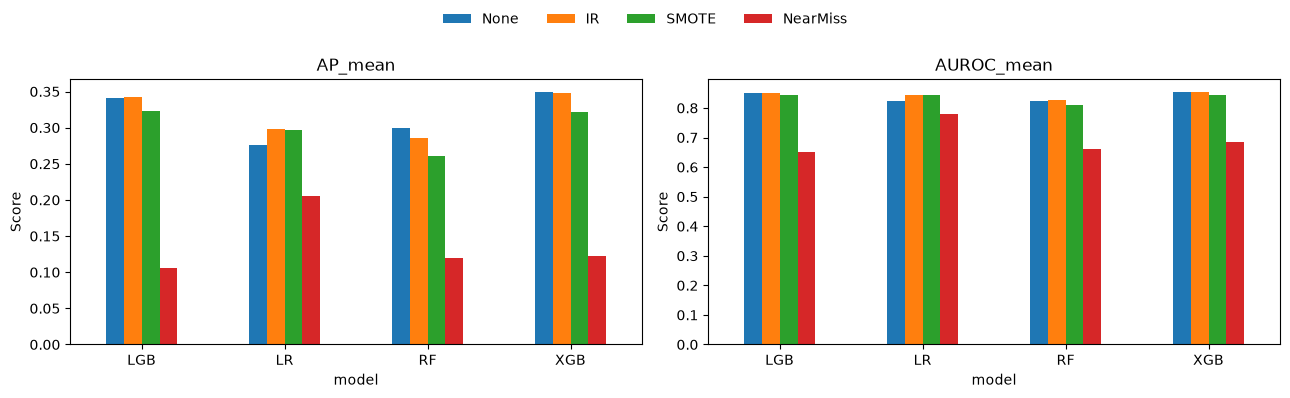

In [19]:
# 보정 방법별 AP/AUROC 비교. 범례는 그래프 위에 공통으로 표시한다.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["AP_mean", "AUROC_mean"]):
    balance_summary.pivot(
        index="model", columns="balance", values=metric,
    ).reindex(columns=balance_methods).plot(kind="bar", ax=ax, rot=0)
    ax.set_title(metric)
    ax.set_ylabel("Score")
    ax.legend_.remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
plt.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig("balance_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


## 8. 보정 없는 XGB 튜닝 및 OOF threshold 선택

- 현재 보정 비교에서 평균 AP 1위인 XGB + None을 튜닝한다. PCA는 사용하지 않는다.
- 기존 분할을 유지하고 AP로 설정을 선택한다. AUROC는 보조로 기록한다.
- 12개 조합 × 5-fold = 60회 학습 후 선택한 설정으로 전체 Train을 재학습한다.
- 기존 XGB 설정(100 trees, depth=4, learning_rate=0.1)도 후보에 포함한다.
- 선택한 설정으로 OOF 예측을 새로 생성하고 F2 최대 threshold를 정한다.
- 파라미터 선택에 같은 Train CV를 사용했으므로 이 OOF 평가도 개발 결과다.
  튜닝·threshold 선택까지 포함한 독립적 CV 추정치는 아니며, 최종 평가는 격리한 Test에서 수행한다.
- 여기서는 Test를 사용하지 않는다. 아래 셀을 순서대로 실행하고 최종 설정을 고정한다.


In [ ]:
# AP 상위 조합이 현재 구현 대상과 일치하는지 확인한다.
# 이후 보정 비교 결과가 바뀌면 조용히 잘못된 파이프라인을 튜닝하지 않도록 멈춘다.
winner = balance_summary.sort_values(
    "AP_mean", ascending=False, kind="stable"
).iloc[0]
assert winner["model"] == "XGB" and winner["balance"] == "None", (
    "현재 셀은 XGB + None 전용입니다. 선정 결과를 확인하세요."
)

tune_pipe = Pipeline([
    ("clean", GMSCPreprocessor(use_log=True)),
    ("scale", StandardScaler()),
    ("model", clone(selected_model["XGB"]).set_params(
        scale_pos_weight=1.0,
        n_jobs=1,
    )),
])

# 단계 이름 model 뒤에 __를 붙여 XGB 파라미터를 지정한다.
param_grid = {
    "model__n_estimators": [100, 250],
    "model__max_depth": [3, 4, 5],
    "model__learning_rate": [0.05, 0.1],
}

search = GridSearchCV(
    estimator=tune_pipe,
    param_grid=param_grid,
    scoring={"AP": "average_precision", "AUROC": "roc_auc"},
    refit="AP",                # 평균 AP 1위 설정으로 전체 Train 재학습
    cv=cv_splits,
    n_jobs=3,                  # XGB 내부 n_jobs=1로 병렬 중첩 제한
    pre_dispatch=3,
    error_score="raise",
    return_train_score=False,
    verbose=1,
)
search.fit(X_train, y_train)

tuning_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_AP")
tuning_results.to_csv("xgb_tuning_results.csv", index=False)

# 전체 Train으로 학습된 최종 후보. 아직 Test로 평가하지 않는다.
tuned_pipe = search.best_estimator_
print("선정 파라미터:", search.best_params_)
print(f"튜닝 CV AP: {search.best_score_:.4f}")
display(tuning_results[[
    "param_model__n_estimators", "param_model__max_depth",
    "param_model__learning_rate", "mean_test_AP", "std_test_AP",
    "mean_test_AUROC", "rank_test_AP",
]])


In [ ]:
from sklearn.model_selection import cross_val_predict

# 전체 Train을 학습한 모델의 예측이 아니라, 각 행을 제외하고 학습한 모델의 예측을 얻는다.
# cross_val_predict는 tuned_pipe를 복제하므로 전체 Train으로 학습된 tuned_pipe는 유지된다.
oof_matrix = cross_val_predict(
    clone(tuned_pipe),
    X_train,
    y_train,
    cv=cv_splits,
    method="predict_proba",
    n_jobs=3,
    pre_dispatch=3,
)
positive_col = list(tuned_pipe.classes_).index(1)
tuned_oof_prob = oof_matrix[:, positive_col]
assert np.isfinite(tuned_oof_prob).all()
assert ((tuned_oof_prob >= 0) & (tuned_oof_prob <= 1)).all()

# OOF를 원래 Train 행 순서와 fold 번호로 저장한다.
tuned_oof_fold = np.zeros(len(X_train), dtype=int)
for fold, (_, valid_idx) in enumerate(cv_splits, start=1):
    tuned_oof_fold[valid_idx] = fold

pd.DataFrame({
    "row_index": X_train.index.to_numpy(),
    "cv_fold": tuned_oof_fold,
    "y_true": y_train.to_numpy(),
    "prob": tuned_oof_prob,
}).to_csv("xgb_tuned_oof.csv", index=False)


In [ ]:
import json

# PR 곡선의 마지막 precision/recall에는 대응 threshold가 없으므로 제외한다.
precision, recall, thresholds = precision_recall_curve(y_train, tuned_oof_prob)
p_values, r_values = precision[:-1], recall[:-1]

# F2 = 5 * Precision * Recall / (4 * Precision + Recall)
denominator = 4 * p_values + r_values
f2_values = np.divide(
    5 * p_values * r_values,
    denominator,
    out=np.zeros_like(denominator),
    where=denominator > 0,
)
best_index = int(np.argmax(f2_values))
best_threshold = float(thresholds[best_index])

# F2가 동일하면 오름차순 threshold 중 첫 값(더 낮은 값)을 선택한다.
threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": p_values,
    "recall": r_values,
    "F2": f2_values,
})
threshold_results.to_csv("xgb_threshold_search.csv", index=False)

# 기본 0.5와 선택 threshold를 비교한다. 두 행 모두 OOF 개발 결과다.
oof_metric_rows = []
for label, threshold in [("Default", 0.5), ("F2 optimized", best_threshold)]:
    pred = (tuned_oof_prob >= threshold).astype(int)
    oof_metric_rows.append({
        "rule": label,
        "threshold": threshold,
        "AP": average_precision_score(y_train, tuned_oof_prob),
        "AUROC": roc_auc_score(y_train, tuned_oof_prob),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0),
        "F2": fbeta_score(y_train, pred, beta=2, zero_division=0),
        "MCC": matthews_corrcoef(y_train, pred),
        "Brier": brier_score_loss(y_train, tuned_oof_prob),
    })
oof_metrics = pd.DataFrame(oof_metric_rows)
oof_metrics.to_csv("xgb_tuned_oof_metrics.csv", index=False)

final_config = {
    "model": "XGB",
    "feature": "Original (8 features + special flag)",
    "use_log": True,
    "balance": "None",
    "seed": SEED,
    "n_splits": len(cv_splits),
    "best_params": search.best_params_,
    "threshold_rule": "Train OOF F2 maximum; ties use lower threshold",
    "threshold": best_threshold,
}
with open("final_config.json", "w", encoding="utf-8") as f:
    json.dump(final_config, f, ensure_ascii=False, indent=2)

print(f"고정할 threshold: {best_threshold:.6f}")
display(oof_metrics)


## 9. 설정 고정 후 최종 Test 평가

- GridSearchCV(refit="AP")가 전체 Train으로 재학습한 tuned_pipe를 사용한다.
- final_config.json에 저장한 Train OOF 기반 F2 threshold를 그대로 적용한다.
- Test는 예측·평가에만 사용한다. Test 성능을 보고 파라미터나 threshold를 다시 선택하지 않는다.
- 기본 threshold 0.5도 사전에 정한 참고 조건으로 보고하며, Test에서 더 좋은 쪽을 다시 고르지 않는다.
- AP/AUROC/Brier는 확률 기반 지표이므로 같은 모델에서 threshold를 바꿔도 값이 같다.
- 실제 양성 1은 데이터에서 정의한 90일 이상 연체 또는 그보다 심각한 상황을 의미한다.


In [ ]:
from sklearn.metrics import confusion_matrix

# Train에서 확정한 설정을 파일에서 읽는다. Test로 threshold를 재계산하지 않는다.
with open("final_config.json", encoding="utf-8") as f:
    frozen_config = json.load(f)
final_threshold = float(frozen_config["threshold"])

# 메모리에 있는 모델이 저장한 튜닝 결과와 같은지 확인한다.
assert frozen_config["model"] == "XGB"
assert frozen_config["balance"] == "None"
for param, value in frozen_config["best_params"].items():
    assert tuned_pipe.get_params()[param] == value, f"설정 불일치: {param}"
assert tuned_pipe.get_params()["model__scale_pos_weight"] == 1.0
assert X_train.index.intersection(X_test.index).empty, "Train/Test 행 중복"

# 이미 전체 Train으로 학습된 모델로 Test의 양성 확률을 한 번 계산한다.
positive_col = list(tuned_pipe.classes_).index(1)
test_prob = tuned_pipe.predict_proba(X_test)[:, positive_col]
assert np.isfinite(test_prob).all()
assert ((test_prob >= 0) & (test_prob <= 1)).all()
test_pred = (test_prob >= final_threshold).astype(int)

test_metric_rows = []
for label, threshold in [("Default", 0.5), ("Train OOF F2 threshold", final_threshold)]:
    pred = (test_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    test_metric_rows.append({
        "rule": label,
        "threshold": threshold,
        "AP": average_precision_score(y_test, test_prob),
        "AUROC": roc_auc_score(y_test, test_prob),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "F2": fbeta_score(y_test, pred, beta=2, zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
        "Brier": brier_score_loss(y_test, test_prob),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    })

test_metrics = pd.DataFrame(test_metric_rows)
test_metrics.to_csv("final_test_metrics.csv", index=False)
pd.DataFrame({
    "row_index": X_test.index.to_numpy(),
    "y_true": y_test.to_numpy(),
    "prob": test_prob,
    "prediction": test_pred,
}).to_csv("final_test_predictions.csv", index=False)

print(f"최종 고정 threshold: {final_threshold:.6f}")
print(f"Test 표본 수: {len(y_test):,}, 양성 비율: {y_test.mean():.4f}")
display(test_metrics)


In [ ]:
# 발표용 최종 평가 그림: 고정된 모델·threshold만 사용한다.
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

PrecisionRecallDisplay.from_predictions(
    y_test, test_prob, ax=axes[0, 0], name="Final XGB",
)
axes[0, 0].axhline(
    y_test.mean(), color="gray", linestyle="--", label="Positive prevalence",
)
axes[0, 0].set_title("Test Precision–Recall curve")
axes[0, 0].legend(loc="best")

RocCurveDisplay.from_predictions(
    y_test, test_prob, ax=axes[0, 1], name="Final XGB",
)
axes[0, 1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[0, 1].set_title("Test ROC curve")

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=[0, 1], display_labels=["0", "1"],
    ax=axes[1, 0], cmap="Blues", colorbar=False,
)
axes[1, 0].set_title(f"Test confusion matrix (threshold={final_threshold:.4f})")

CalibrationDisplay.from_predictions(
    y_test, test_prob, n_bins=10, strategy="quantile",
    ax=axes[1, 1], name="Final XGB",
)
axes[1, 1].set_title("Test calibration curve (quantile bins)")

plt.tight_layout()
fig.savefig("final_test_evaluation.png", dpi=200, bbox_inches="tight")
plt.show()


### 9.1. 고정된 기준 모델 간 탐색적 paired bootstrap

- 초기 CV와 같은 기준 설정의 XGB_None·LGB_None·XGB_IR을 전체 Train에서 학습해 Test 확률을 계산했다. 튜닝된 최종 XGB와 구분한다.
- 동일 Test 행을 두 모델에 공통으로 재추출한다. 양성·음성별 1,000회 재추출로 관측 클래스 비율을 유지한다.
- ΔAP = A - B의 percentile 95% 구간을 계산했다. 이것은 CV 평균 차이(0.3498 vs 0.3405)의 신뢰구간이 아니다.
- 고정 모델과 행 단위 재추출 가정에 조건부인 Test 표본 불확실성이며, 재학습·튜닝·후보 선택의 변동성은 포함하지 않는다.
- Test 확인 후 추가한 탐색적 두 비교다. 사전 지정 검정 또는 다중 비교를 보정한 동시 구간으로 주장하지 않는다.


In [ ]:
# 모델 재선정 없이 조건부 신뢰구간과 효과 크기를 보고한다.
bootstrap_ci = pd.read_csv("submission/supplementary/paired_bootstrap_ci.csv")
display(bootstrap_ci)
display(Image(filename="submission/supplementary/paired_bootstrap_ci.png"))


## 10. 마지막 추가 튜닝 및 발표자료

- 마지막 Train 전용 탐색: 20개 후보 × 기존 5-fold.
- 기존 최적 설정이 다시 선정됐으며 CV AP=0.350750로 추가 향상 없음.
- Test는 다시 평가하지 않았고 기존 고정 모델의 Test 결과를 유지.
- 재현 스크립트: presentation_build/final_tuning.py
- 결과: submission/followup_tuning_results.csv
- 발표자료: submission/GMSC_7min.pptx (본문 8장 + 부록 2장)
- 대본: submission/발표대본_7분.txt
- 제출 정리: submission/결과정리_제출안내.txt


## 11. 기준 6개 모델과 튜닝 XGB의 Test Recall 비교

- 6개 기준 모델과 튜닝 XGB는 threshold=0.5로 비교한다.
- 튜닝 XGB의 Train OOF F2 threshold 결과는 별도 표시한다.
- Recall만으로 비교하면 오탐 비용을 숨길 수 있어 Precision·F2·FP도 함께 저장한다.
- 기존 Test를 확인한 뒤 추가한 설명용 비교이며 최종 모델 재선정에 사용하지 않는다.


기준 LR Recall 평가
기준 DT Recall 평가
기준 RF Recall 평가
기준 ET Recall 평가
기준 LGB Recall 평가
기준 XGB Recall 평가


,label,model,condition,threshold,Recall,Precision,F2,AP,AUROC,TP,FN,FP,TN
0,LR,LR,"Baseline, threshold=0.5",0.500000,0.018454,0.336364,0.022755,0.283491,0.832107,37,1968,73,27922
1,DT,DT,"Baseline, threshold=0.5",0.500000,0.257357,0.235509,0.252669,0.110419,0.598976,516,1489,1675,26320
2,RF,RF,"Baseline, threshold=0.5",0.500000,0.149127,0.459293,0.172414,0.301160,0.826797,299,1706,352,27643
3,ET,ET,"Baseline, threshold=0.5",0.500000,0.149127,0.420534,0.171229,0.266374,0.814682,299,1706,412,27583
4,LGB,LGB,"Baseline, threshold=0.5",0.500000,0.106733,0.543147,0.127169,0.336837,0.855835,214,1791,180,27815
5,XGB,XGB,"Baseline, threshold=0.5",0.500000,0.097756,0.561605,0.117099,0.349288,0.858870,196,1809,153,27842
6,Tuned XGB,XGB,"Tuned, threshold=0.5",0.500000,0.101746,0.569832,0.121747,0.348774,0.858027,204,1801,154,27841
7,Tuned XGB + F2 threshold,XGB,"Tuned, Train OOF F2 threshold",0.100395,0.665835,0.257027,0.505146,0.348774,0.858027,1335,670,3859,24136


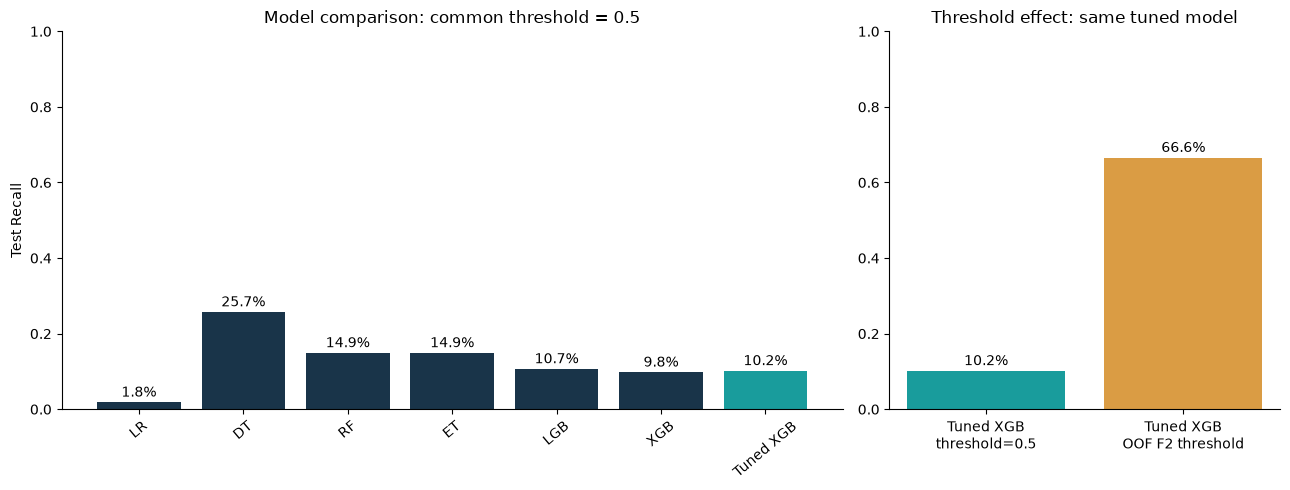

In [25]:
# 같은 Test에서 기준 모델과 최종 모델을 기술적으로 비교한다.
# 이 표를 보고 모델을 다시 선택하거나 threshold를 변경하지 않는다.
from pathlib import Path
import json
from sklearn.metrics import confusion_matrix

recall_out = Path("submission")
recall_out.mkdir(exist_ok=True)
recall_rows = []

def recall_metrics(label, model_name, prob, threshold, condition):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {
        "label": label, "model": model_name, "condition": condition,
        "threshold": threshold,
        "Recall": recall_score(y_test, pred, zero_division=0),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "F2": fbeta_score(y_test, pred, beta=2, zero_division=0),
        "AP": average_precision_score(y_test, prob),
        "AUROC": roc_auc_score(y_test, prob),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
    }

# 기준 6개 모델: 최초 설정 그대로 전체 Train에 학습, 공통 threshold=0.5.
for name in ["LR", "DT", "RF", "ET", "LGB", "XGB"]:
    print(f"기준 {name} Recall 평가", flush=True)
    baseline_pipe = Pipeline([
        ("clean", GMSCPreprocessor(use_log=True)),
        ("scale", StandardScaler()),
        ("model", clone(models[name])),
    ])
    baseline_pipe.fit(X_train, y_train)
    positive_col = list(baseline_pipe.classes_).index(1)
    prob = baseline_pipe.predict_proba(X_test)[:, positive_col]
    recall_rows.append(recall_metrics(
        name, name, prob, 0.5, "Baseline, threshold=0.5"
    ))

# 최종 모델은 이미 저장된 Test 확률을 재사용한다. Test에서 재튜닝하지 않는다.
frozen_predictions = pd.read_csv("final_test_predictions.csv")
assert np.array_equal(frozen_predictions["row_index"].to_numpy(), X_test.index.to_numpy())
assert np.array_equal(frozen_predictions["y_true"].to_numpy(), y_test.to_numpy())
with open("final_config.json", encoding="utf-8") as f:
    frozen = json.load(f)
frozen_prob = frozen_predictions["prob"].to_numpy()

recall_rows.append(recall_metrics(
    "Tuned XGB", "XGB", frozen_prob, 0.5, "Tuned, threshold=0.5"
))
recall_rows.append(recall_metrics(
    "Tuned XGB + F2 threshold", "XGB", frozen_prob,
    float(frozen["threshold"]), "Tuned, Train OOF F2 threshold"
))

recall_comparison = pd.DataFrame(recall_rows)
recall_comparison.to_csv(recall_out / "recall_comparison.csv", index=False)
display(recall_comparison)

# 모델 차이와 threshold 효과를 두 개의 그래프로 구분한다.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
baseline_and_tuned = recall_comparison.iloc[:7]
axes[0].bar(
    baseline_and_tuned["label"], baseline_and_tuned["Recall"],
    color=["#193449"] * 6 + ["#199C9C"],
)
axes[0].set_title("Model comparison: common threshold = 0.5")
axes[0].tick_params(axis="x", rotation=40)
axes[0].set_ylabel("Test Recall")

final_two = recall_comparison.iloc[6:]
axes[1].bar(
    ["Tuned XGB\nthreshold=0.5", "Tuned XGB\nOOF F2 threshold"],
    final_two["Recall"], color=["#199C9C", "#DA9C44"],
)
axes[1].set_title("Threshold effect: same tuned model")
for ax in axes:
    ax.set_ylim(0, 1)
    for bar in ax.patches:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015,
                f"{bar.get_height():.1%}", ha="center", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(recall_out / "recall_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


## 12. 최종 모델 joblib 내보내기

전처리·스케일러·XGB 파이프라인과 Train OOF 임계값을 함께 저장하고 재로드 결과를 검증한다.


In [27]:
from export_final_model import export_final_model
import joblib

# tuned_pipe는 GridSearchCV(refit="AP")가 전체 Train으로 학습한 모델이다.
with open("final_config.json", encoding="utf-8") as f:
    export_config = json.load(f)

model_artifact = export_final_model(
    tuned_pipe, export_config, X_train.iloc[:32],
    output="submission/final_model.joblib",
)

# 새 세션에서도 gmsc_preprocessing.py를 import할 수 있는 환경에서 로드한다.
loaded_artifact = joblib.load("submission/final_model.joblib")
loaded_pipeline = loaded_artifact["pipeline"]
loaded_threshold = loaded_artifact["threshold"]

# 예측 시 기본 predict() 대신 저장한 threshold를 적용한다.
sample = X_train.iloc[:5][loaded_artifact["input_columns"]]
positive_col = list(loaded_pipeline.classes_).index(loaded_artifact["positive_label"])
sample_prob = loaded_pipeline.predict_proba(sample)[:, positive_col]
sample_pred = (sample_prob >= loaded_threshold).astype(int)
print("저장된 threshold:", loaded_threshold)
print("예측 예시:", sample_pred)


저장·재로드 검증 완료: C:\dev\USW_AlgorythmAnalysis\ass\submission\final_model.joblib
저장된 threshold: 0.10039499402046204
예측 예시: [0 0 0 0 0]


## 13. 외부 benchmark 모델 참고 비교

- benchmark는 다른 데이터 또는 다른 분할로 학습했다. 현재 Test와 학습 표본의 중복 여부가 확인되지 않아 독립적인 우열 검증은 아니다.
- 두 모델을 추가 학습하지 않고 현재 Test 30,000건에 적용했다.
- benchmark는 원본명 8개 컬럼, 현재 모델은 저장된 전처리·스케일러·XGB 파이프라인을 사용한다.
- benchmark의 외부 전처리는 제공되지 않아 원본 수치로 입력했다. 별도 전처리가 있었다면 재확인이 필요하다.
- 공통 임계값 0.5를 비교하고, 현재 모델의 F2 임계값 결과는 별도 행으로 표시한다.
- 재현 명령: `.\.venv\Scripts\python.exe benchmark\compare_models.py`.


,model,threshold_rule,threshold,AP,AUROC,Precision,Recall,F1,F2,MCC,Brier,TP,FN,FP,TN
0,Benchmark XGB,Common threshold 0.5,0.500000,0.372394,0.866005,0.587719,0.100249,0.171282,0.120187,0.223980,0.050513,201,1804,141,27854
1,Final XGB,Common threshold 0.5,0.500000,0.348774,0.858027,0.569832,0.101746,0.172662,0.121747,0.221350,0.051415,204,1801,154,27841
2,Final XGB,Train OOF F2 threshold,0.100395,0.348774,0.858027,0.257027,0.665835,0.370885,0.505146,0.348492,0.051415,1335,670,3859,24136


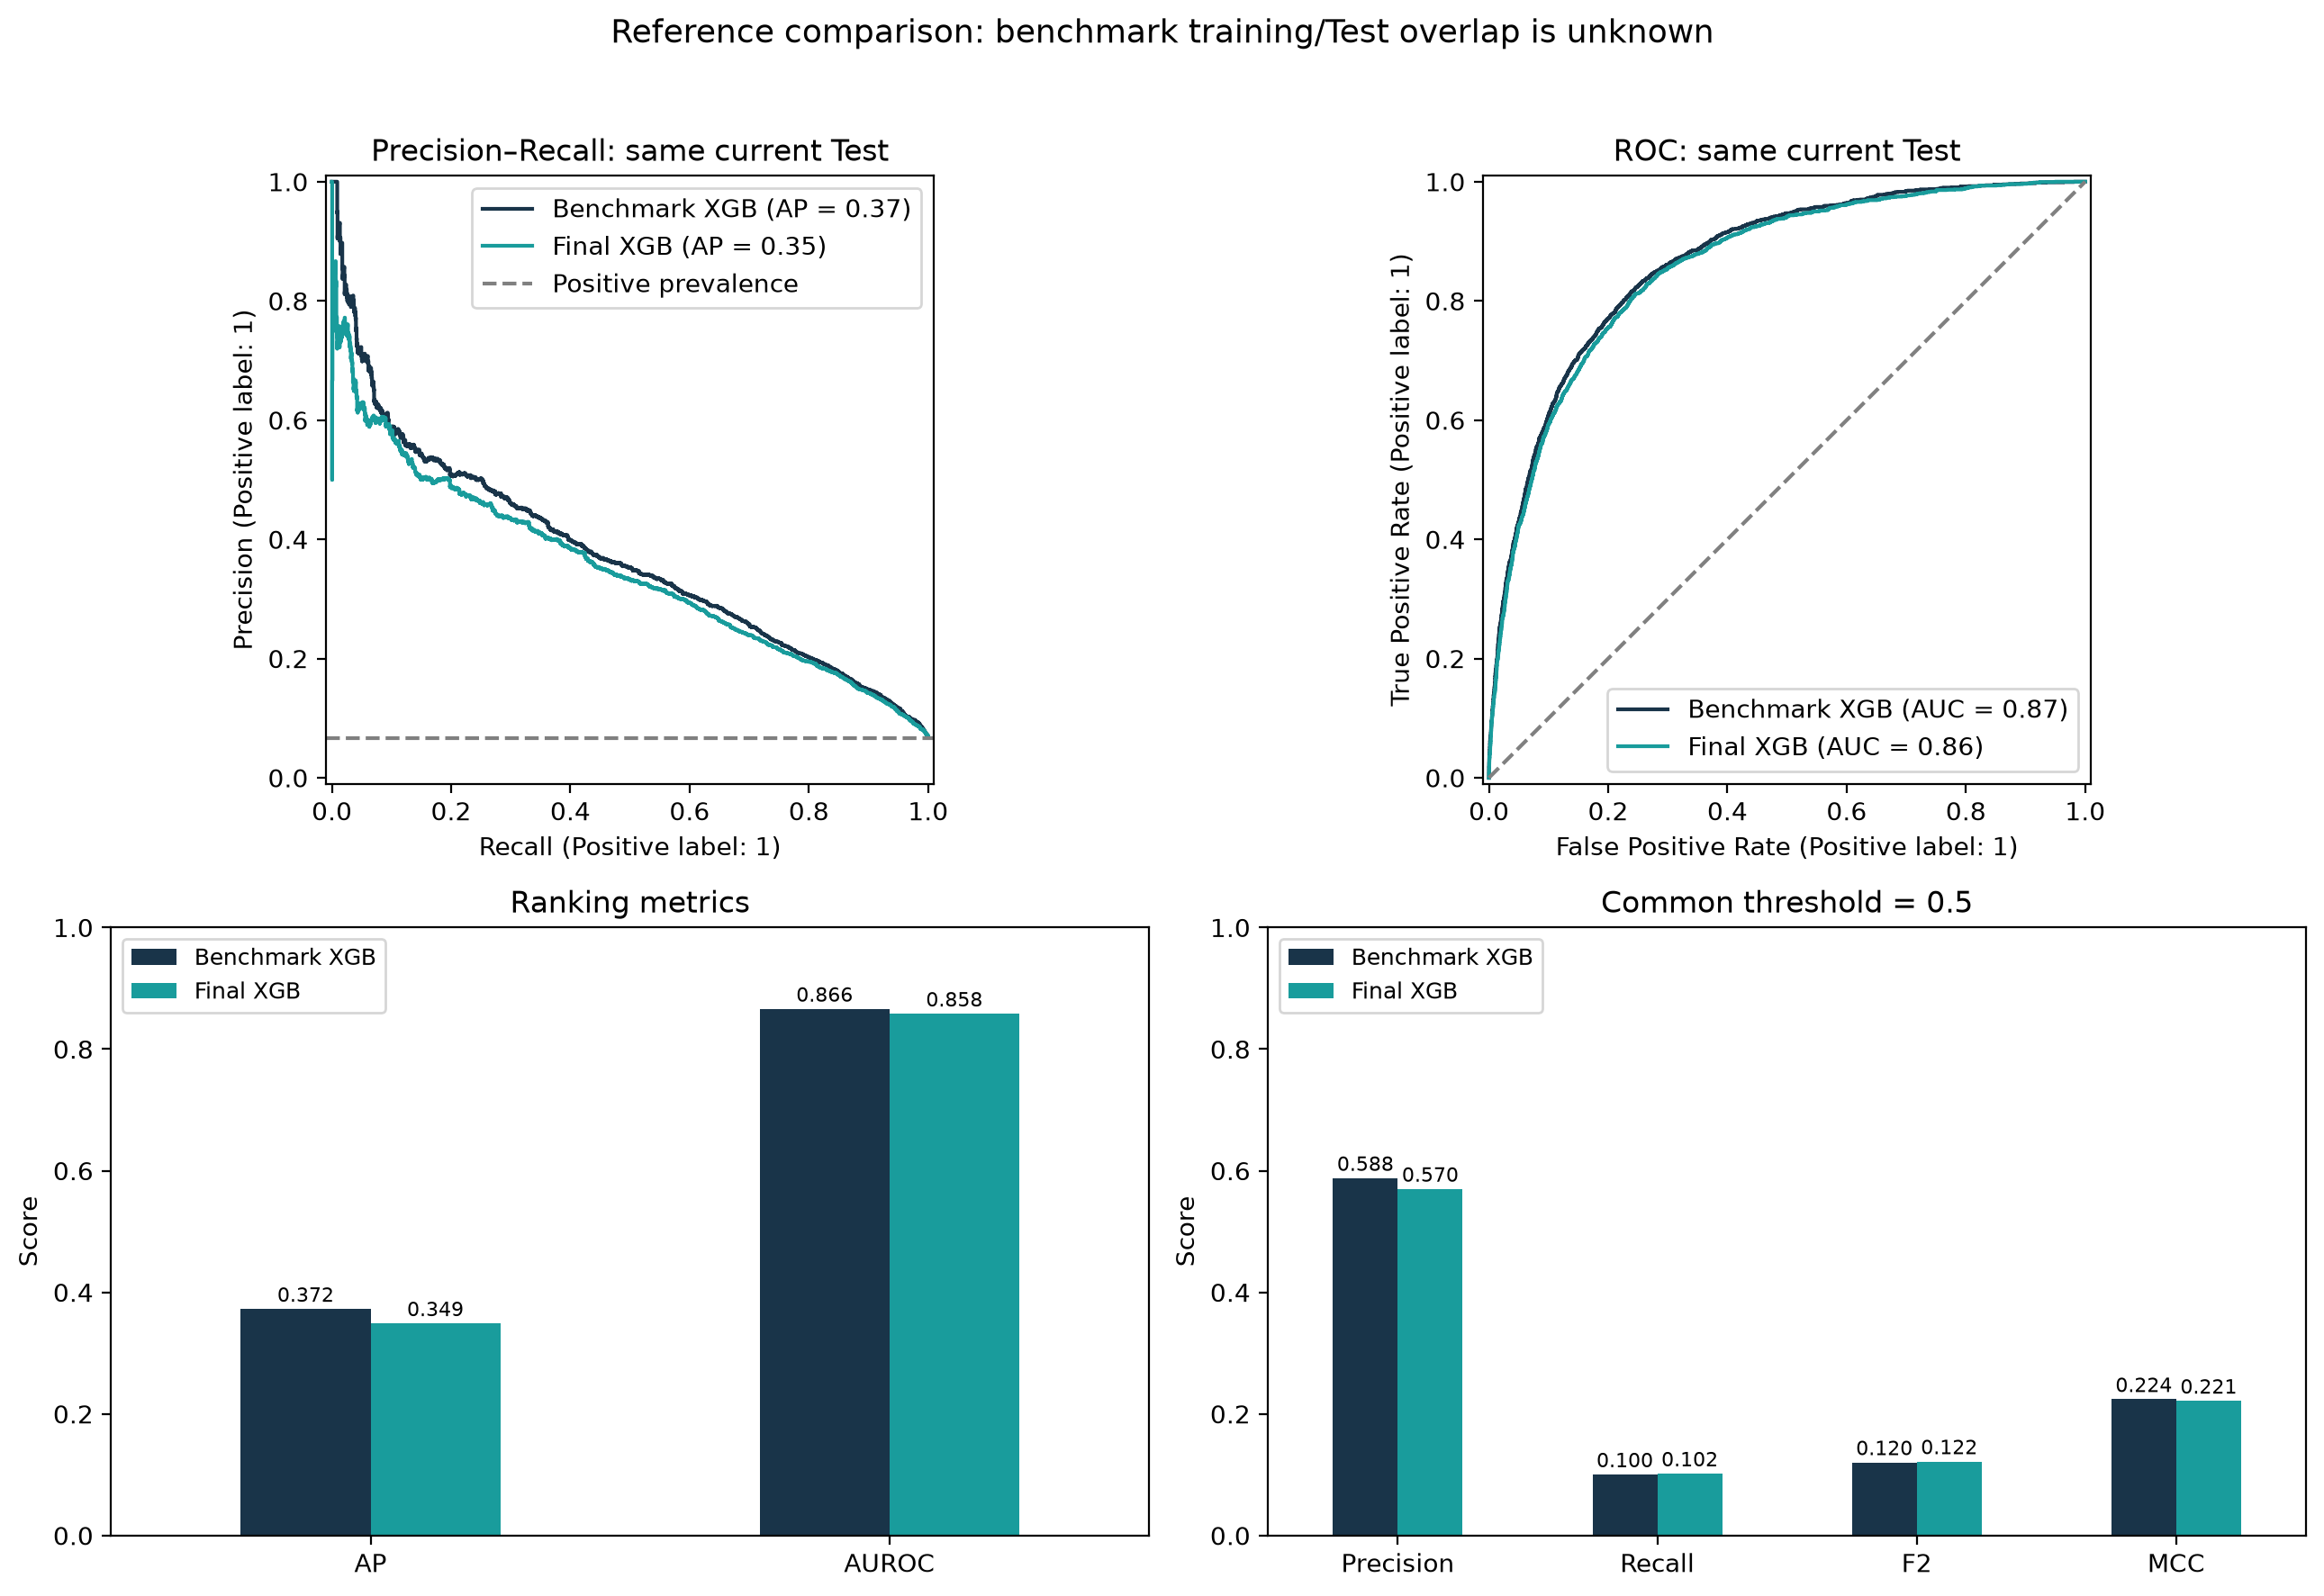

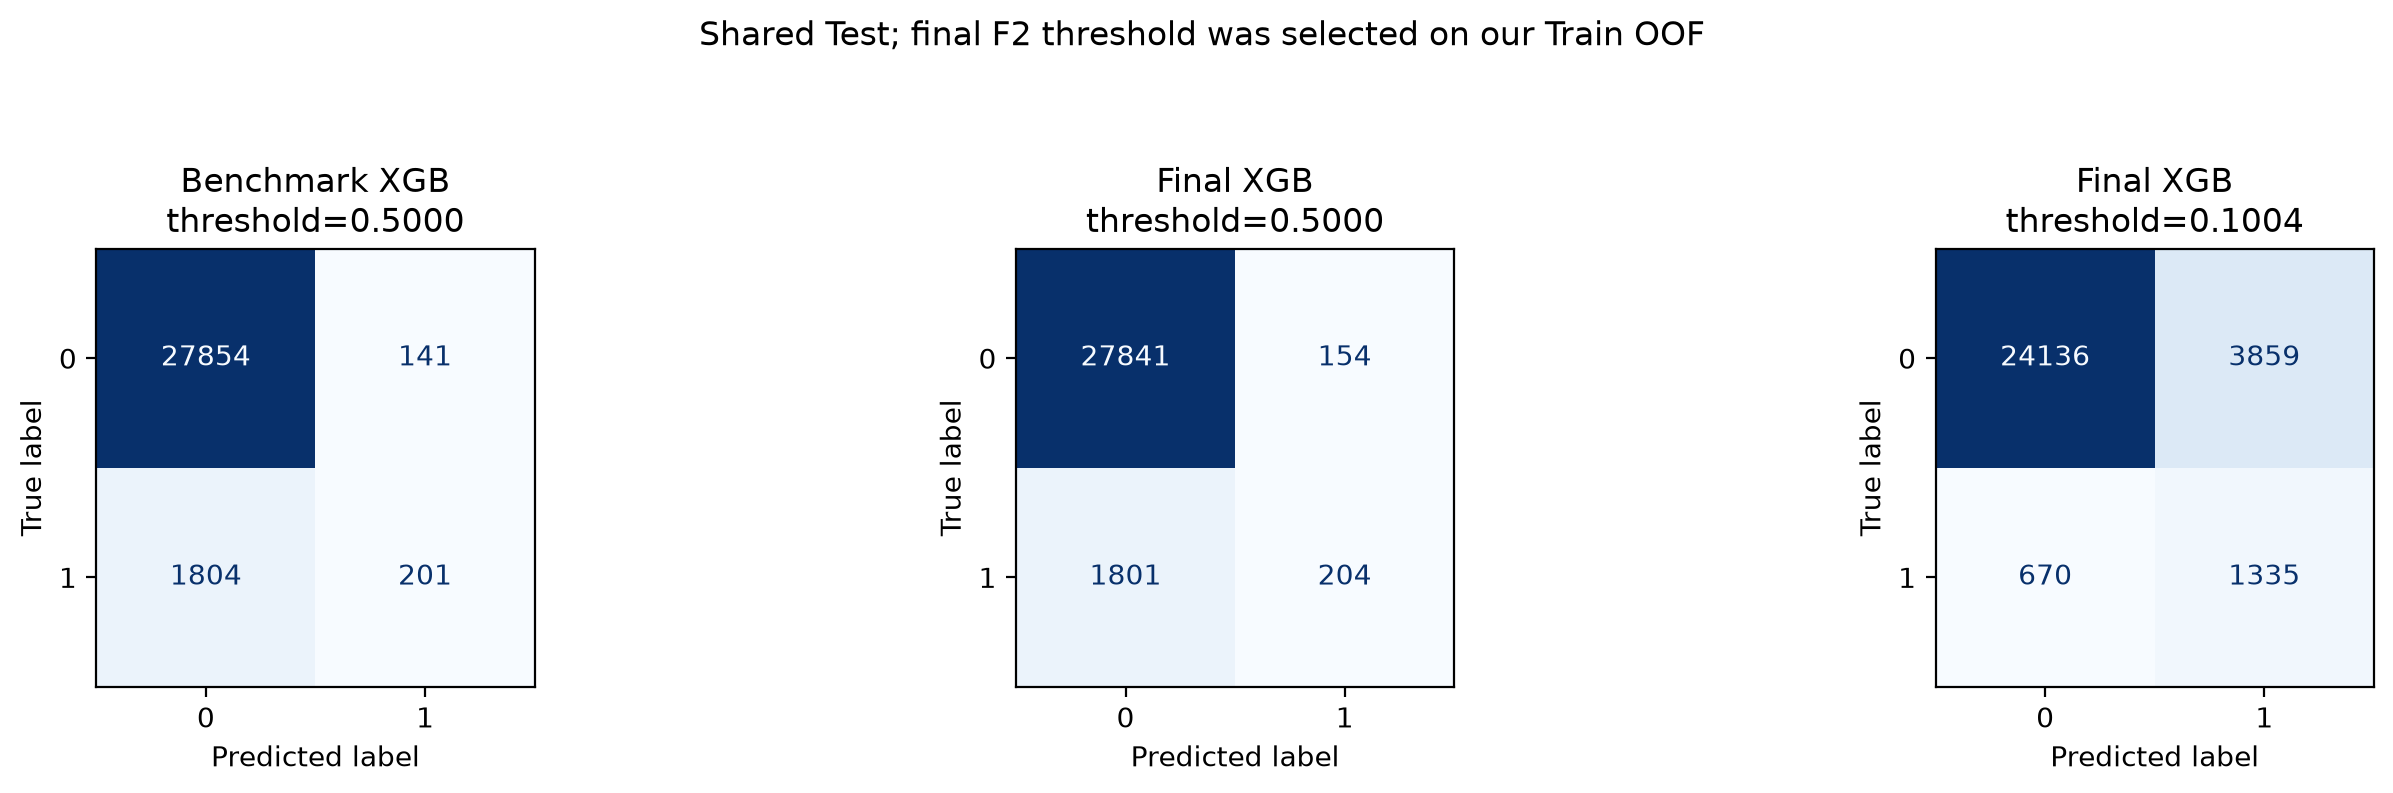

In [28]:
from IPython.display import Image, display

# 실행 완료된 비교 결과를 표시한다. 이 표를 보고 최종 모델을 다시 선택하지 않는다.
benchmark_results = pd.read_csv("submission/benchmark_comparison/metrics.csv")
display(benchmark_results)
display(Image(filename="submission/benchmark_comparison/model_comparison.png"))
display(Image(filename="submission/benchmark_comparison/confusion_matrices.png"))


## 14. 최종 모델 TreeSHAP XAI 분석

- 저장된 최종 파이프라인을 변경하지 않고 학습된 전처리만 적용한다.
- Train 실제 표본 100건을 배경으로 Test 층화 표본 1,000건을 설명한다.
- TreeExplainer의 interventional 방식, model_output="raw"를 사용한다.
- 이진 XGB에서 raw SHAP 값은 log-odds 단위다. 기준값+기여도 합계에 sigmoid를 적용하면 예측 확률이다.
- 그래프의 특성 값도 모델에 입력한 로그·z-score 변환값이다. 원 단위 개별 입력은 local_cases.csv에 기록한다.
- 전역 중요도는 표본 평균 |SHAP|다. 높은 값이 항상 양성 방향이라는 뜻은 아니므로 beeswarm을 함께 본다.
- SHAP은 인과 효과가 아니다. 배경 표본과 상관된 특성의 처리 가정에 따라 기여도가 달라질 수 있다.
- 사례는 높은/낮은 예측 및 오탐/미탐을 의도적으로 선택했다. 고위험 예측이 정답이라는 뜻은 아니다.


In [29]:
import shap
from xai_analysis import run_xai

# 재학습·튜닝 없이 설명을 계산하고, SHAP 합계와 모델 raw 점수의 일치를 검증한다.
xai_report = run_xai()
print("SHAP 버전:", shap.__version__)
print("최대 합계 검증 오차:", xai_report["max_additivity_error"])


c:\dev\USW_AlgorythmAnalysis\ass\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


             feature  mean_abs_shap
             RevUtil       0.639070
         CombDefault       0.554250
                 Age       0.248022
           DebtRatio       0.163461
              Income       0.083278
       PastDue_30-59       0.057459
          CombCredit       0.040813
          Dependents       0.019543
PastDue_special_flag       0.001630
          case  row_index  probability  y_true  prediction
     high_risk     139197     0.638620       0           1
      low_risk      88369     0.003898       0           0
false_positive      76785     0.595775       0           1
false_negative     114551     0.024145       1           0
XAI 저장 완료: C:\dev\USW_AlgorythmAnalysis\ass\submission\xai; additivity error=0.00000390
SHAP 버전: 0.54.1
최대 합계 검증 오차: 3.901510086556925e-06


,feature,mean_abs_shap
0,RevUtil,0.639070
1,CombDefault,0.554250
2,Age,0.248022
3,DebtRatio,0.163461
4,Income,0.083278
5,PastDue_30-59,0.057459
6,CombCredit,0.040813
7,Dependents,0.019543
8,PastDue_special_flag,0.001630


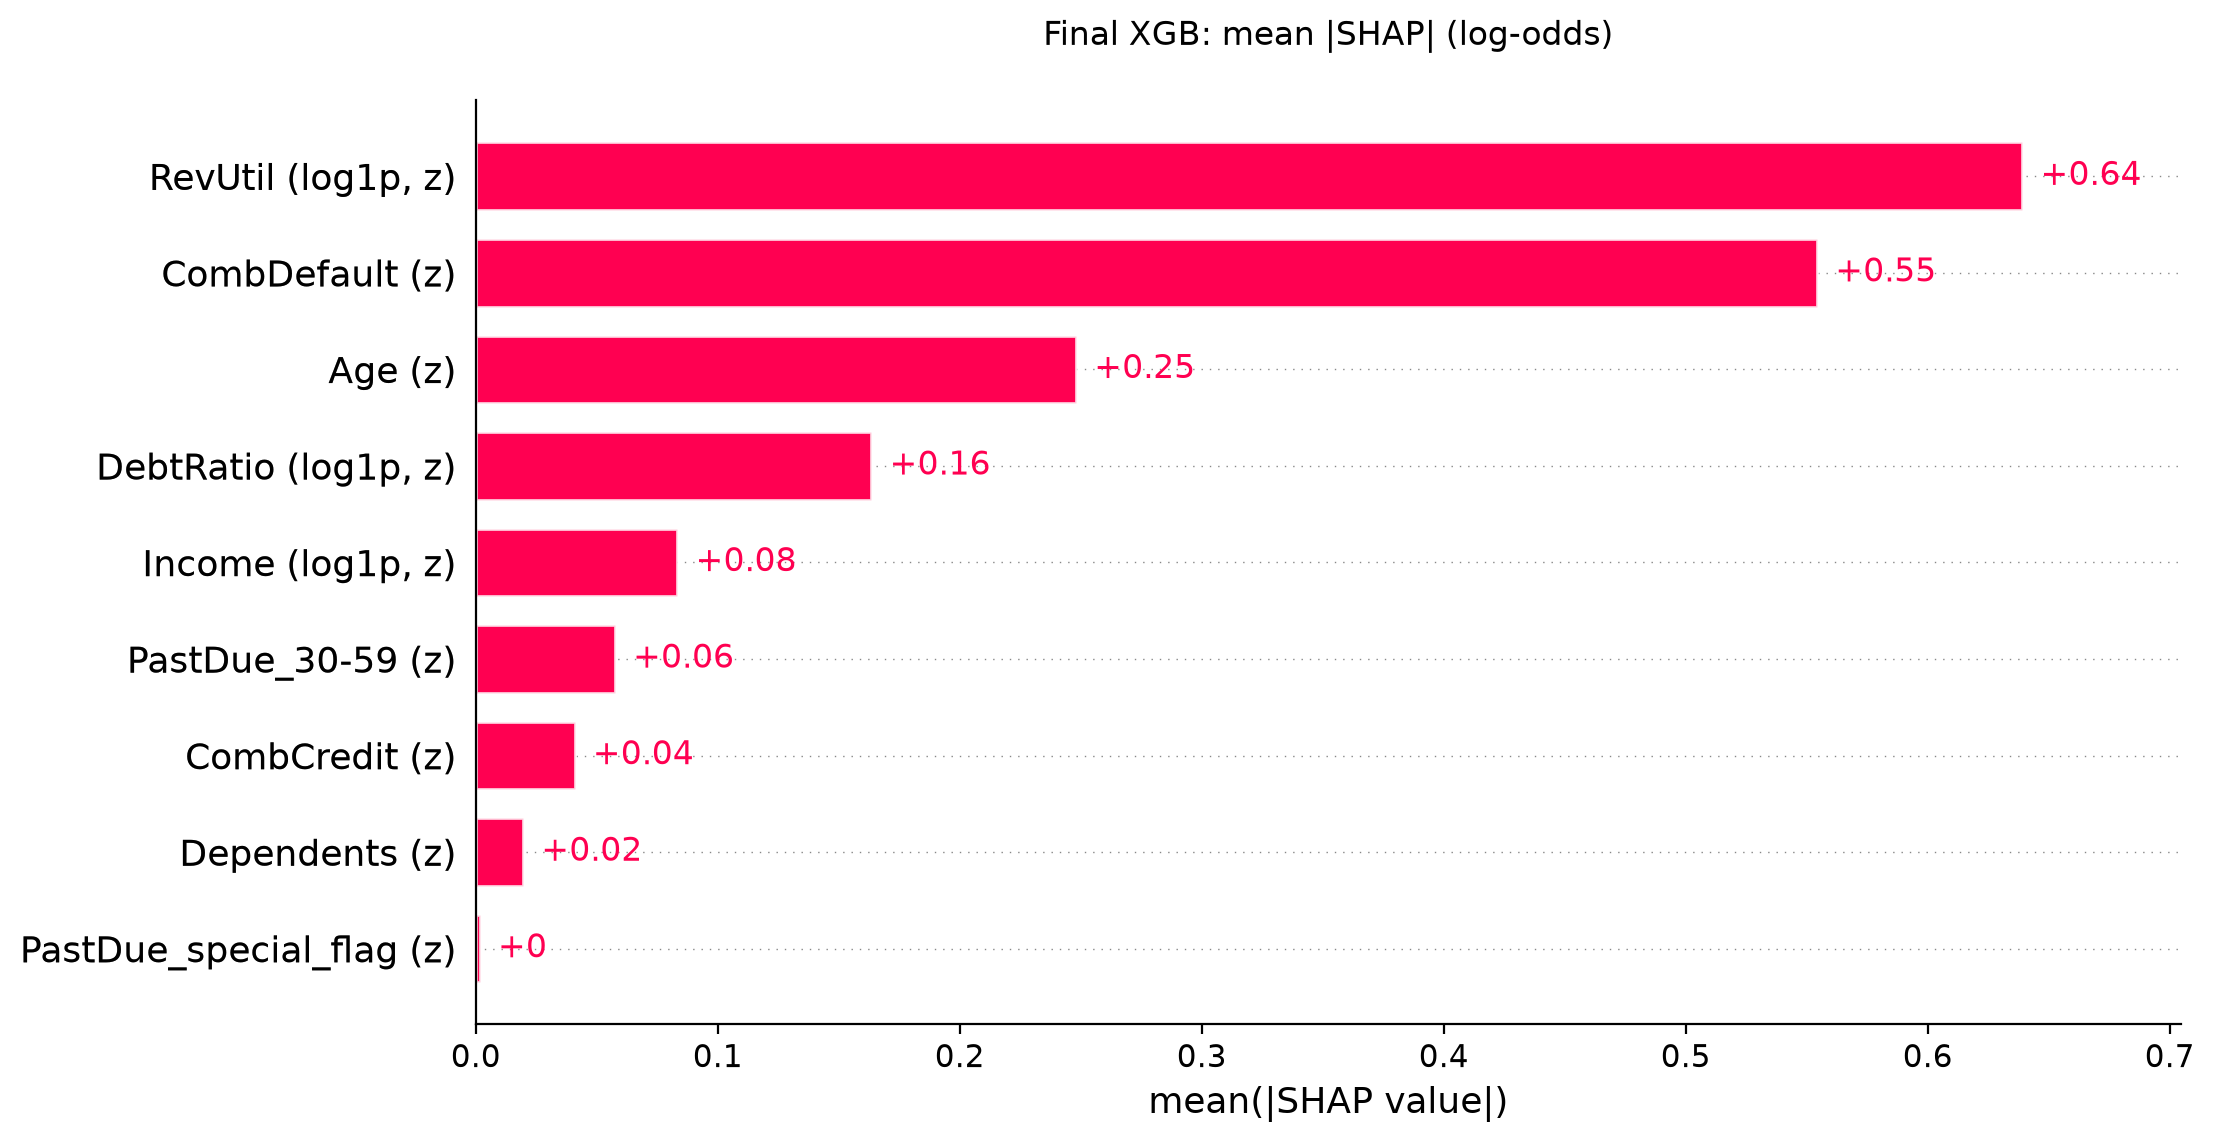

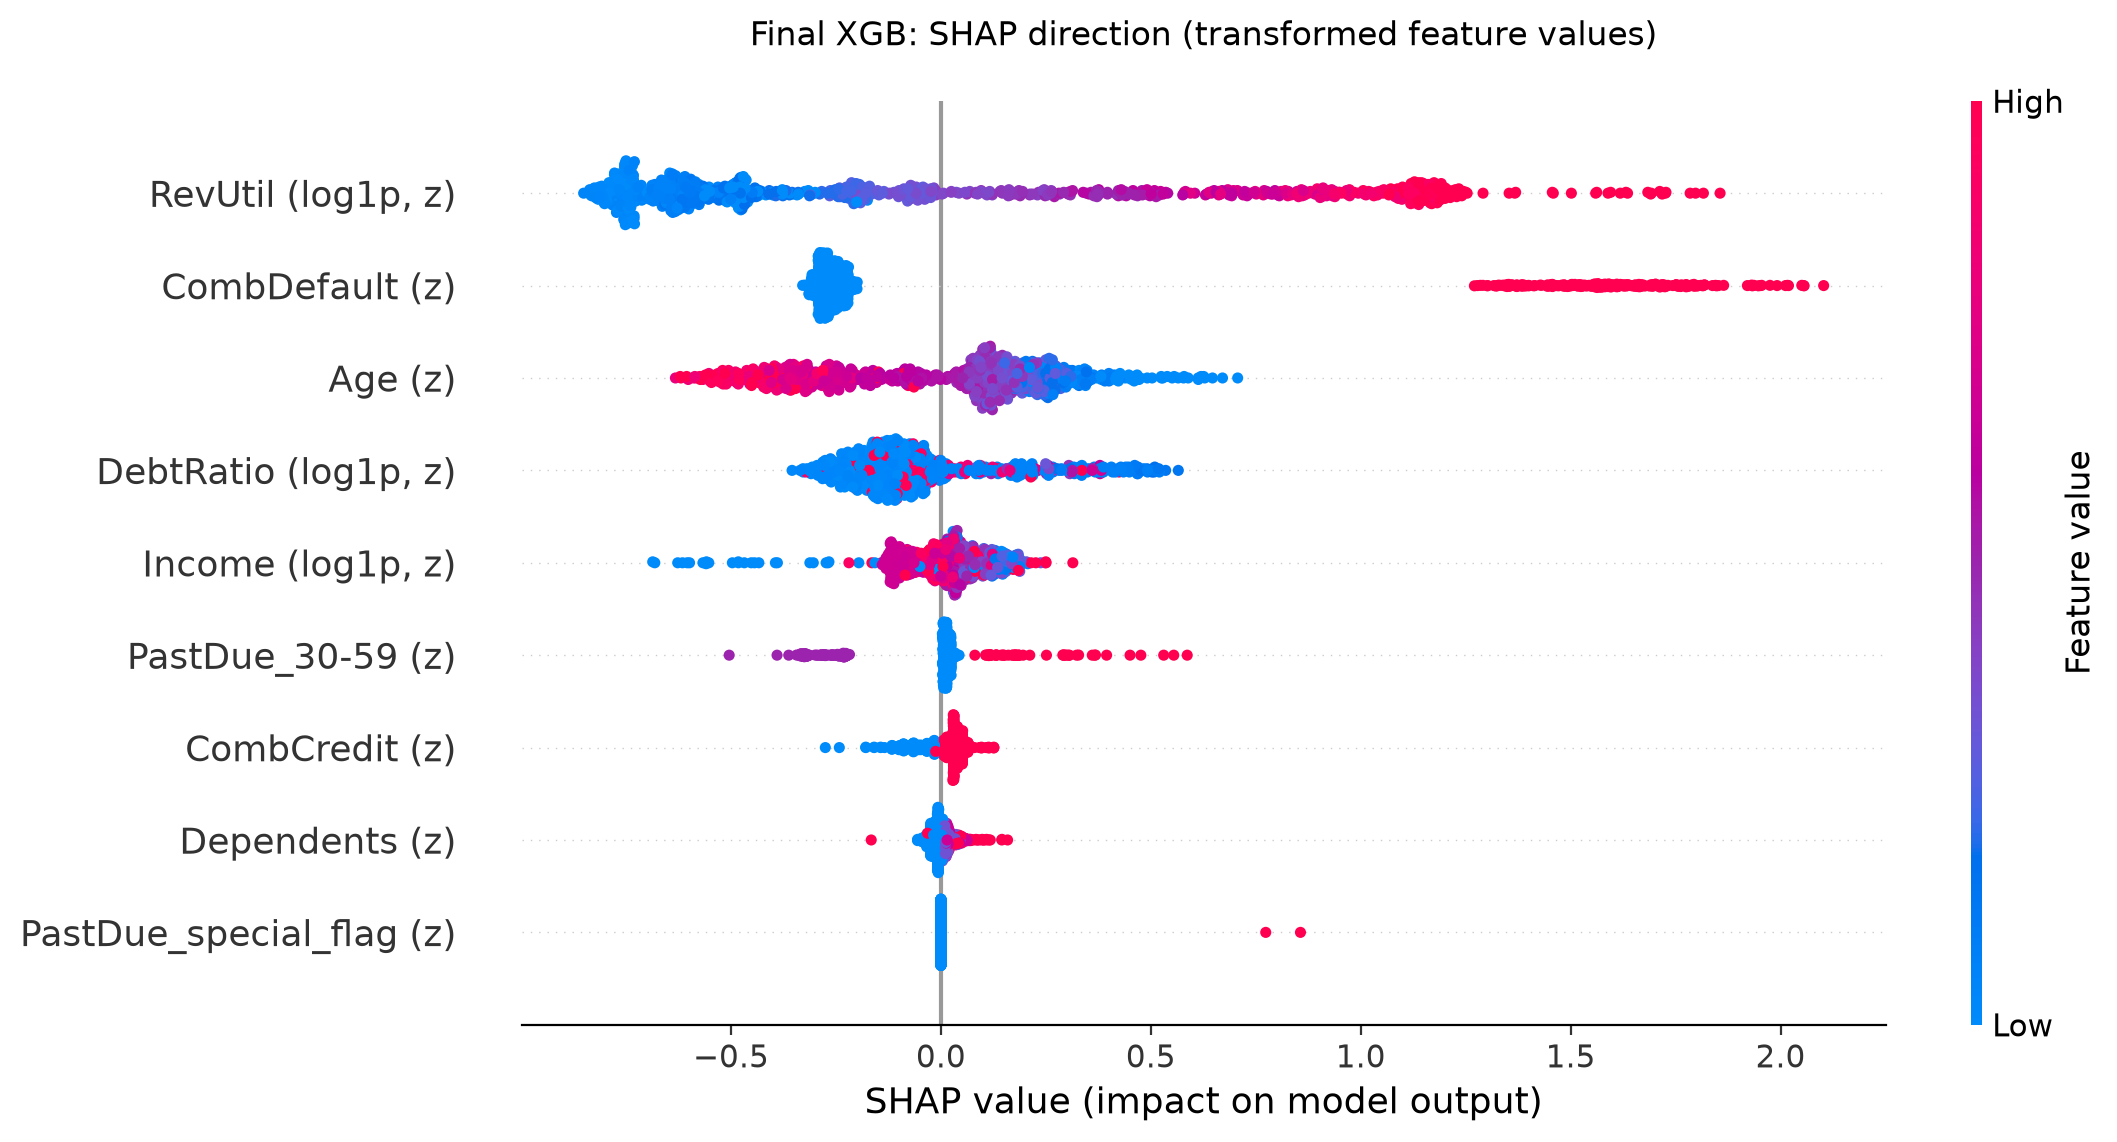

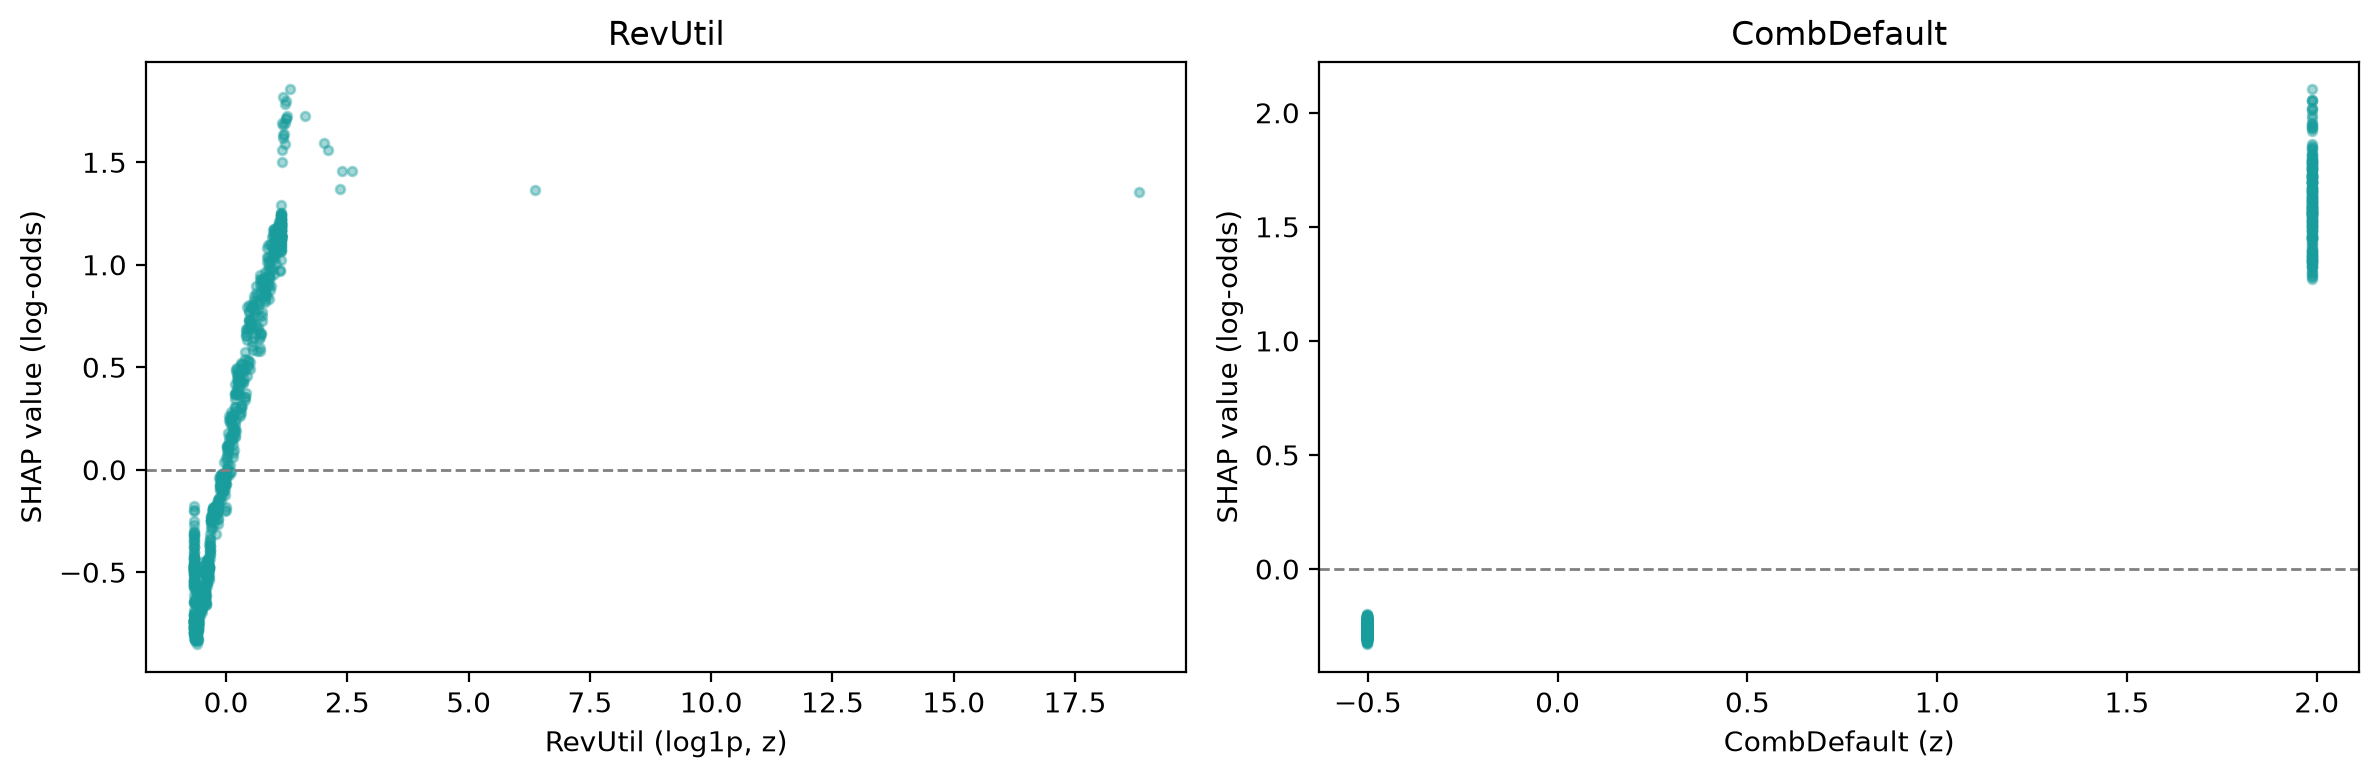

,case,row_index,y_true,prediction,probability,threshold,base_log_odds,output_log_odds,raw_RevUtil,raw_Age,raw_PastDue_30-59,raw_DebtRatio,raw_Income,raw_Dependents,raw_CombDefault,raw_CombCredit
0,high_risk,139197,0,1,0.638620,0.100395,-3.53966,0.569380,1.000000,33.0,98.0,0.008055,3475.0,2.0,1.0,0.0
1,low_risk,88369,0,0,0.003898,0.100395,-3.53966,-5.543374,0.038385,72.0,0.0,2482.000000,6746.0,0.0,0.0,0.0
2,false_positive,76785,0,1,0.595775,0.100395,-3.53966,0.387891,0.983389,28.0,4.0,0.246584,3000.0,1.0,1.0,1.0
3,false_negative,114551,1,0,0.024145,0.100395,-3.53966,-3.699245,0.326570,61.0,0.0,0.161356,3420.0,0.0,0.0,1.0


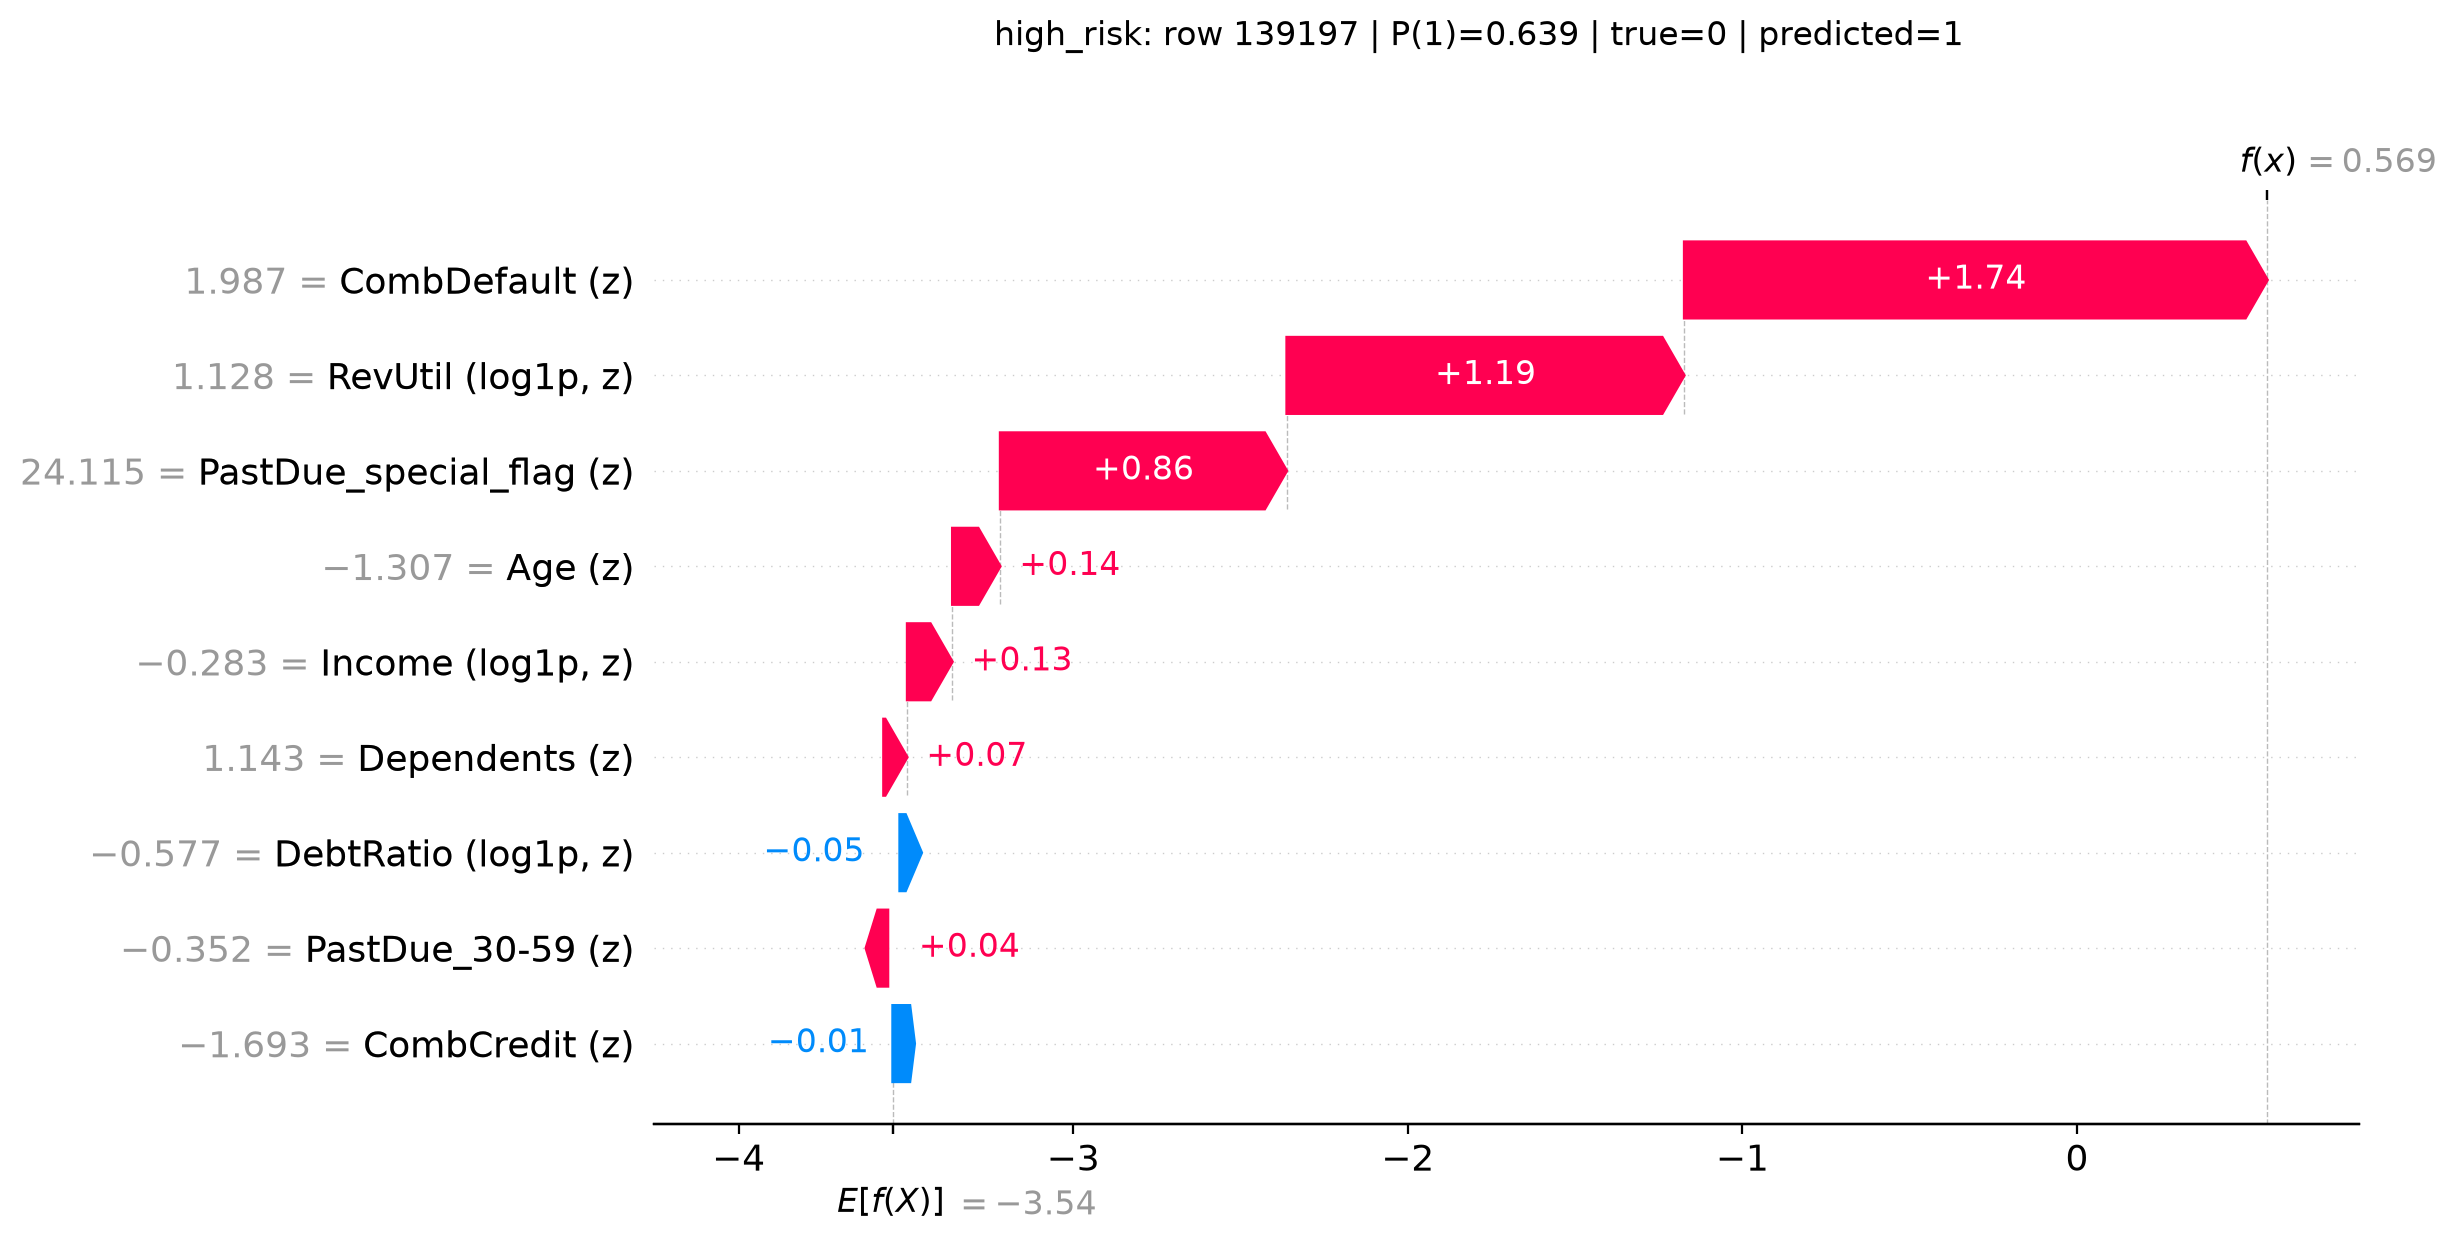

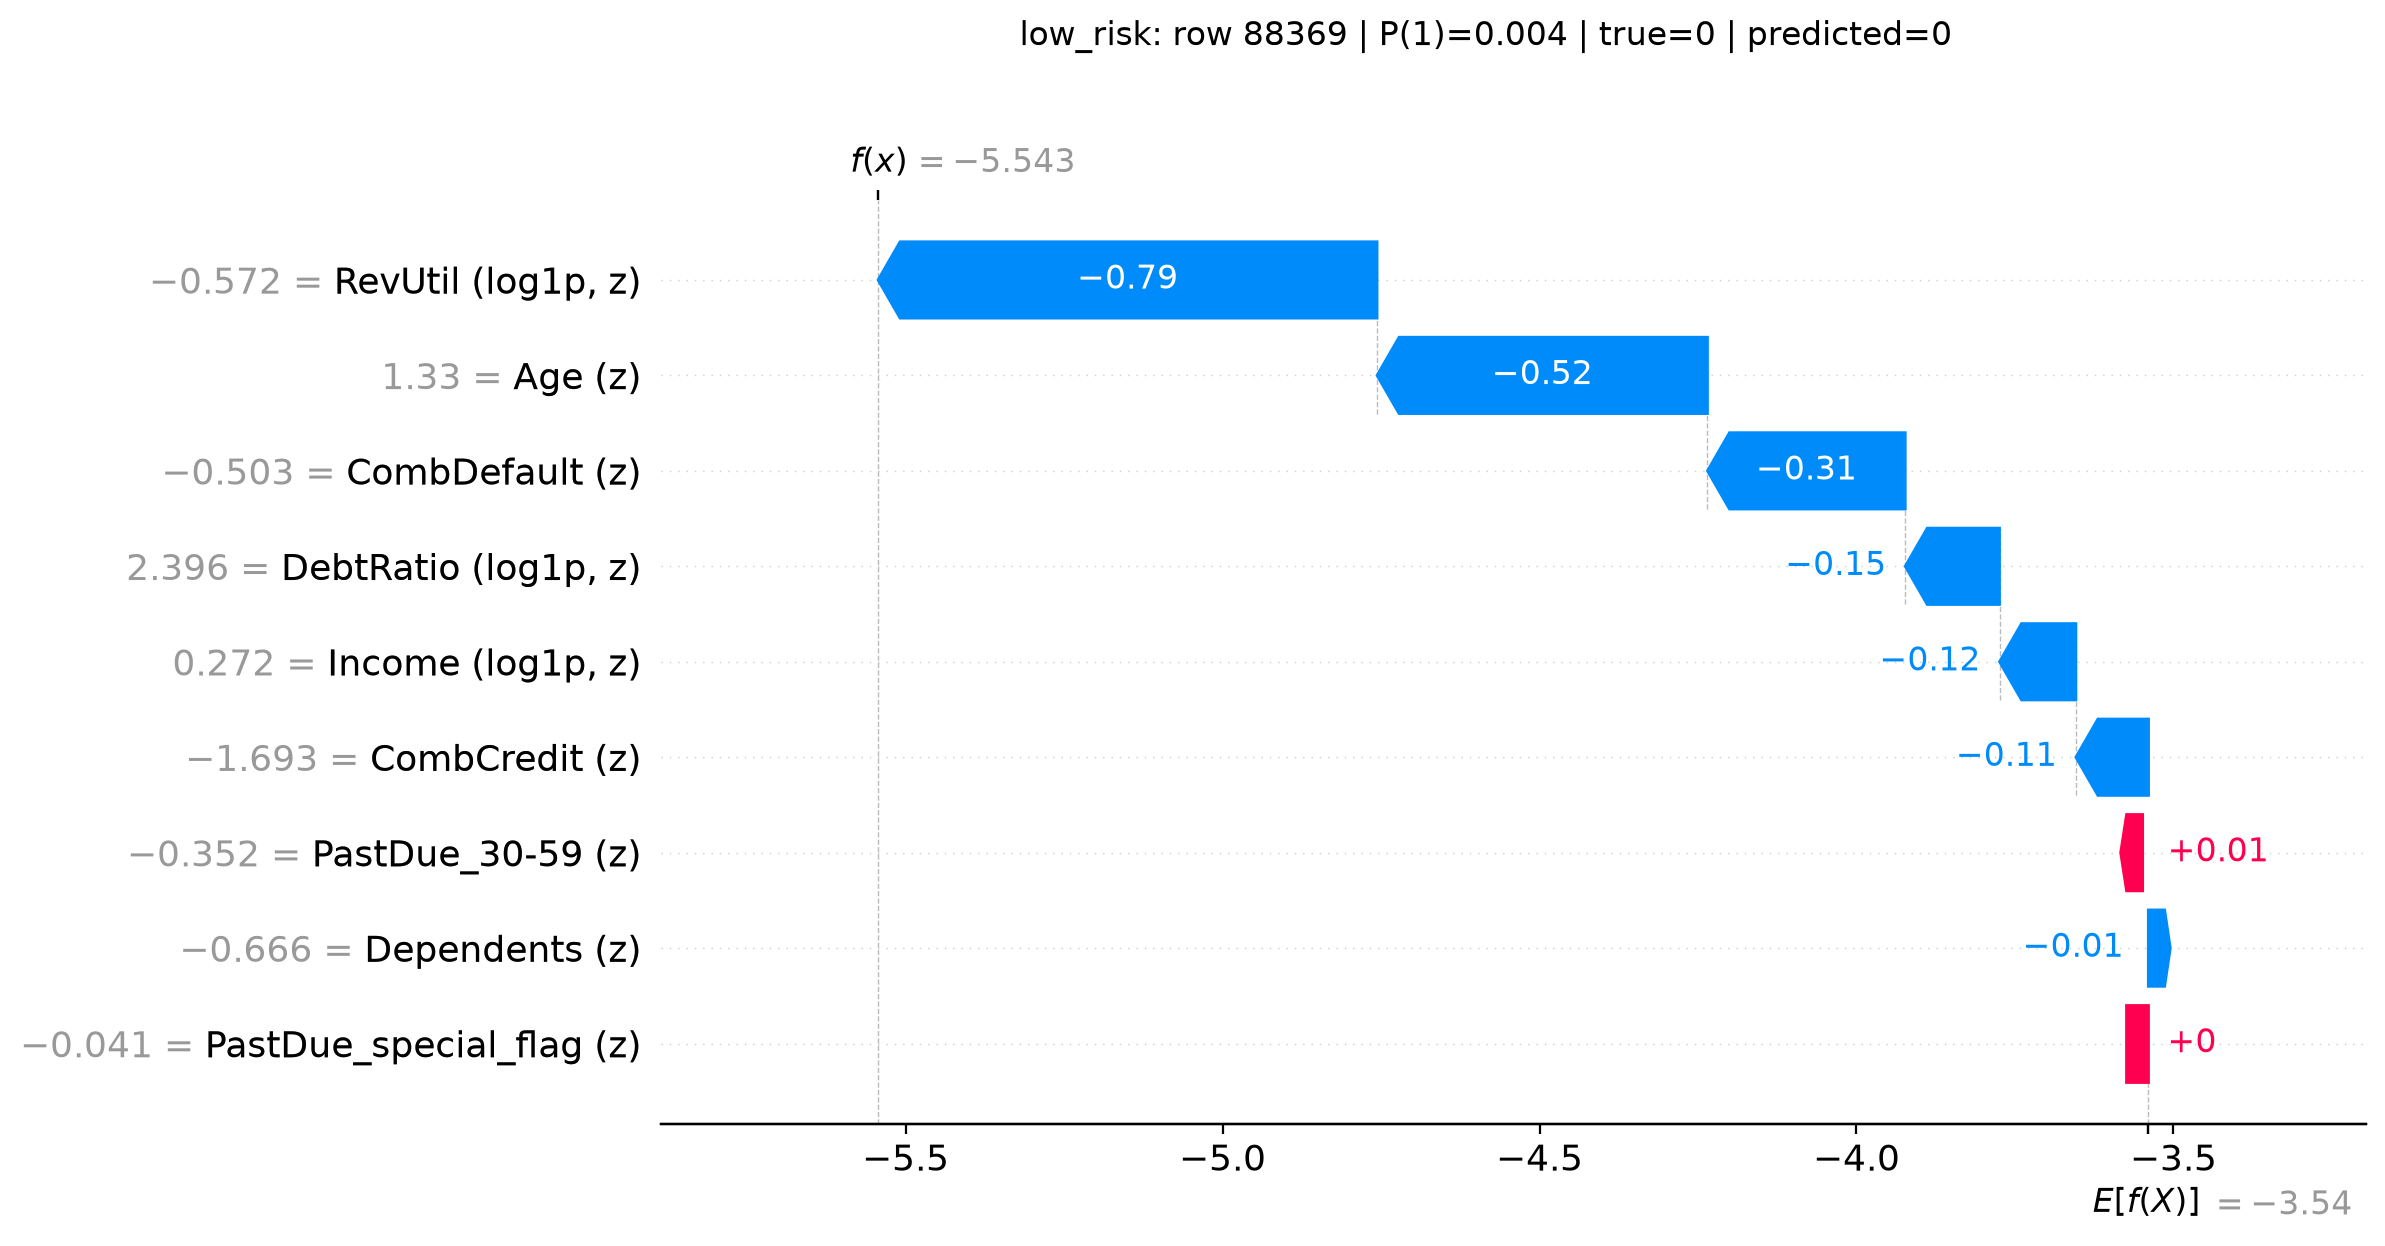

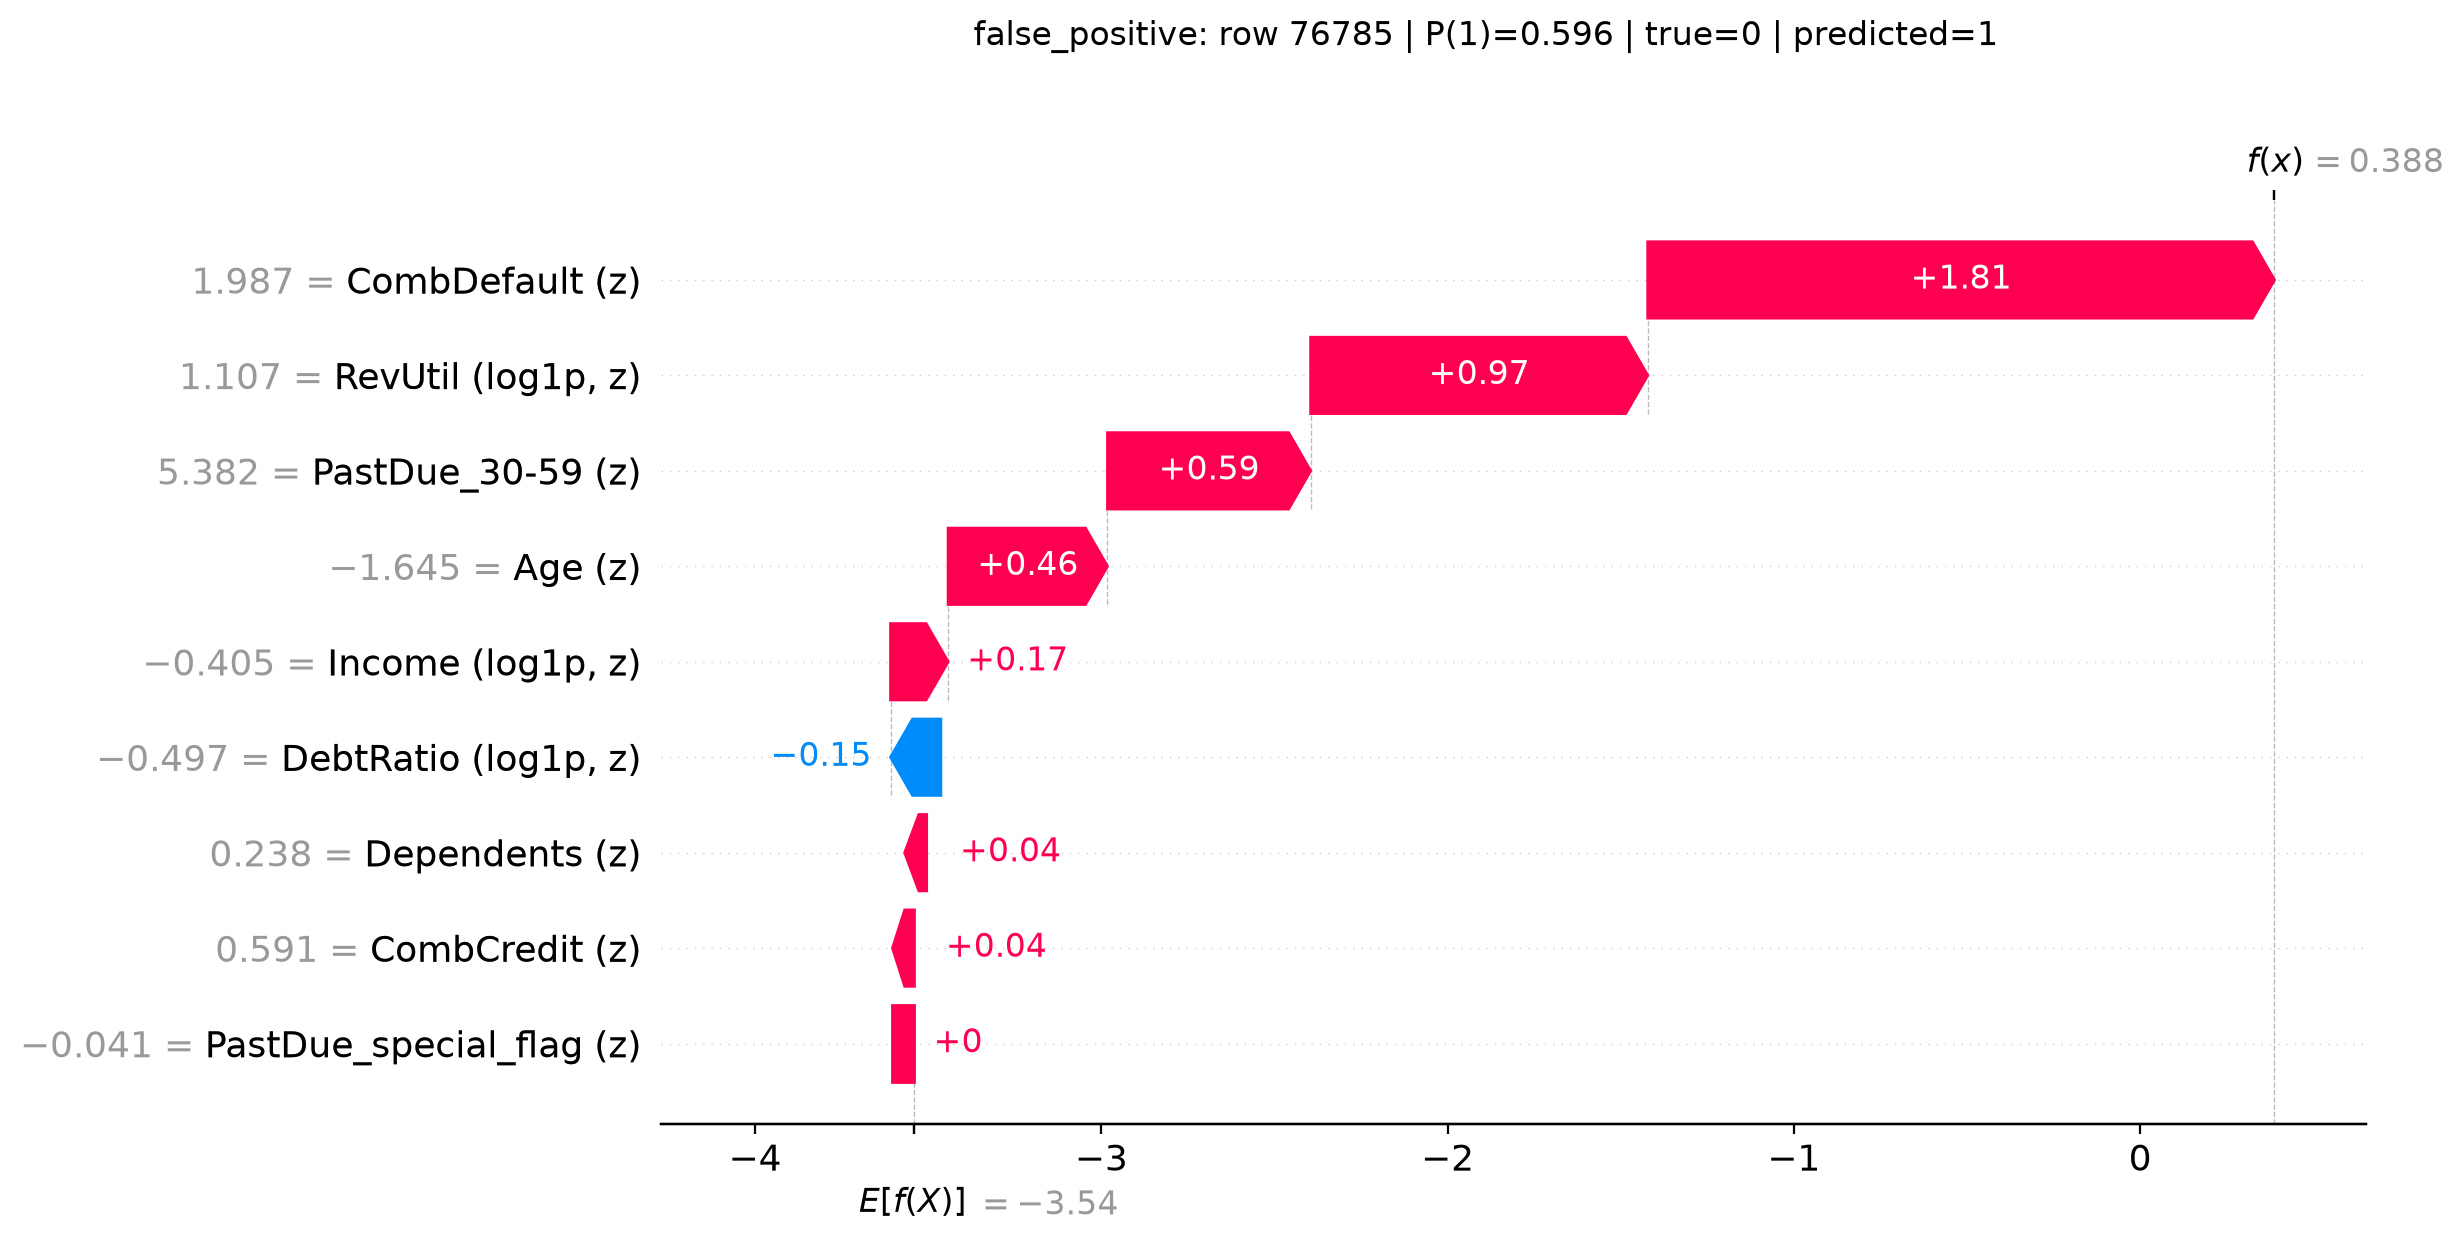

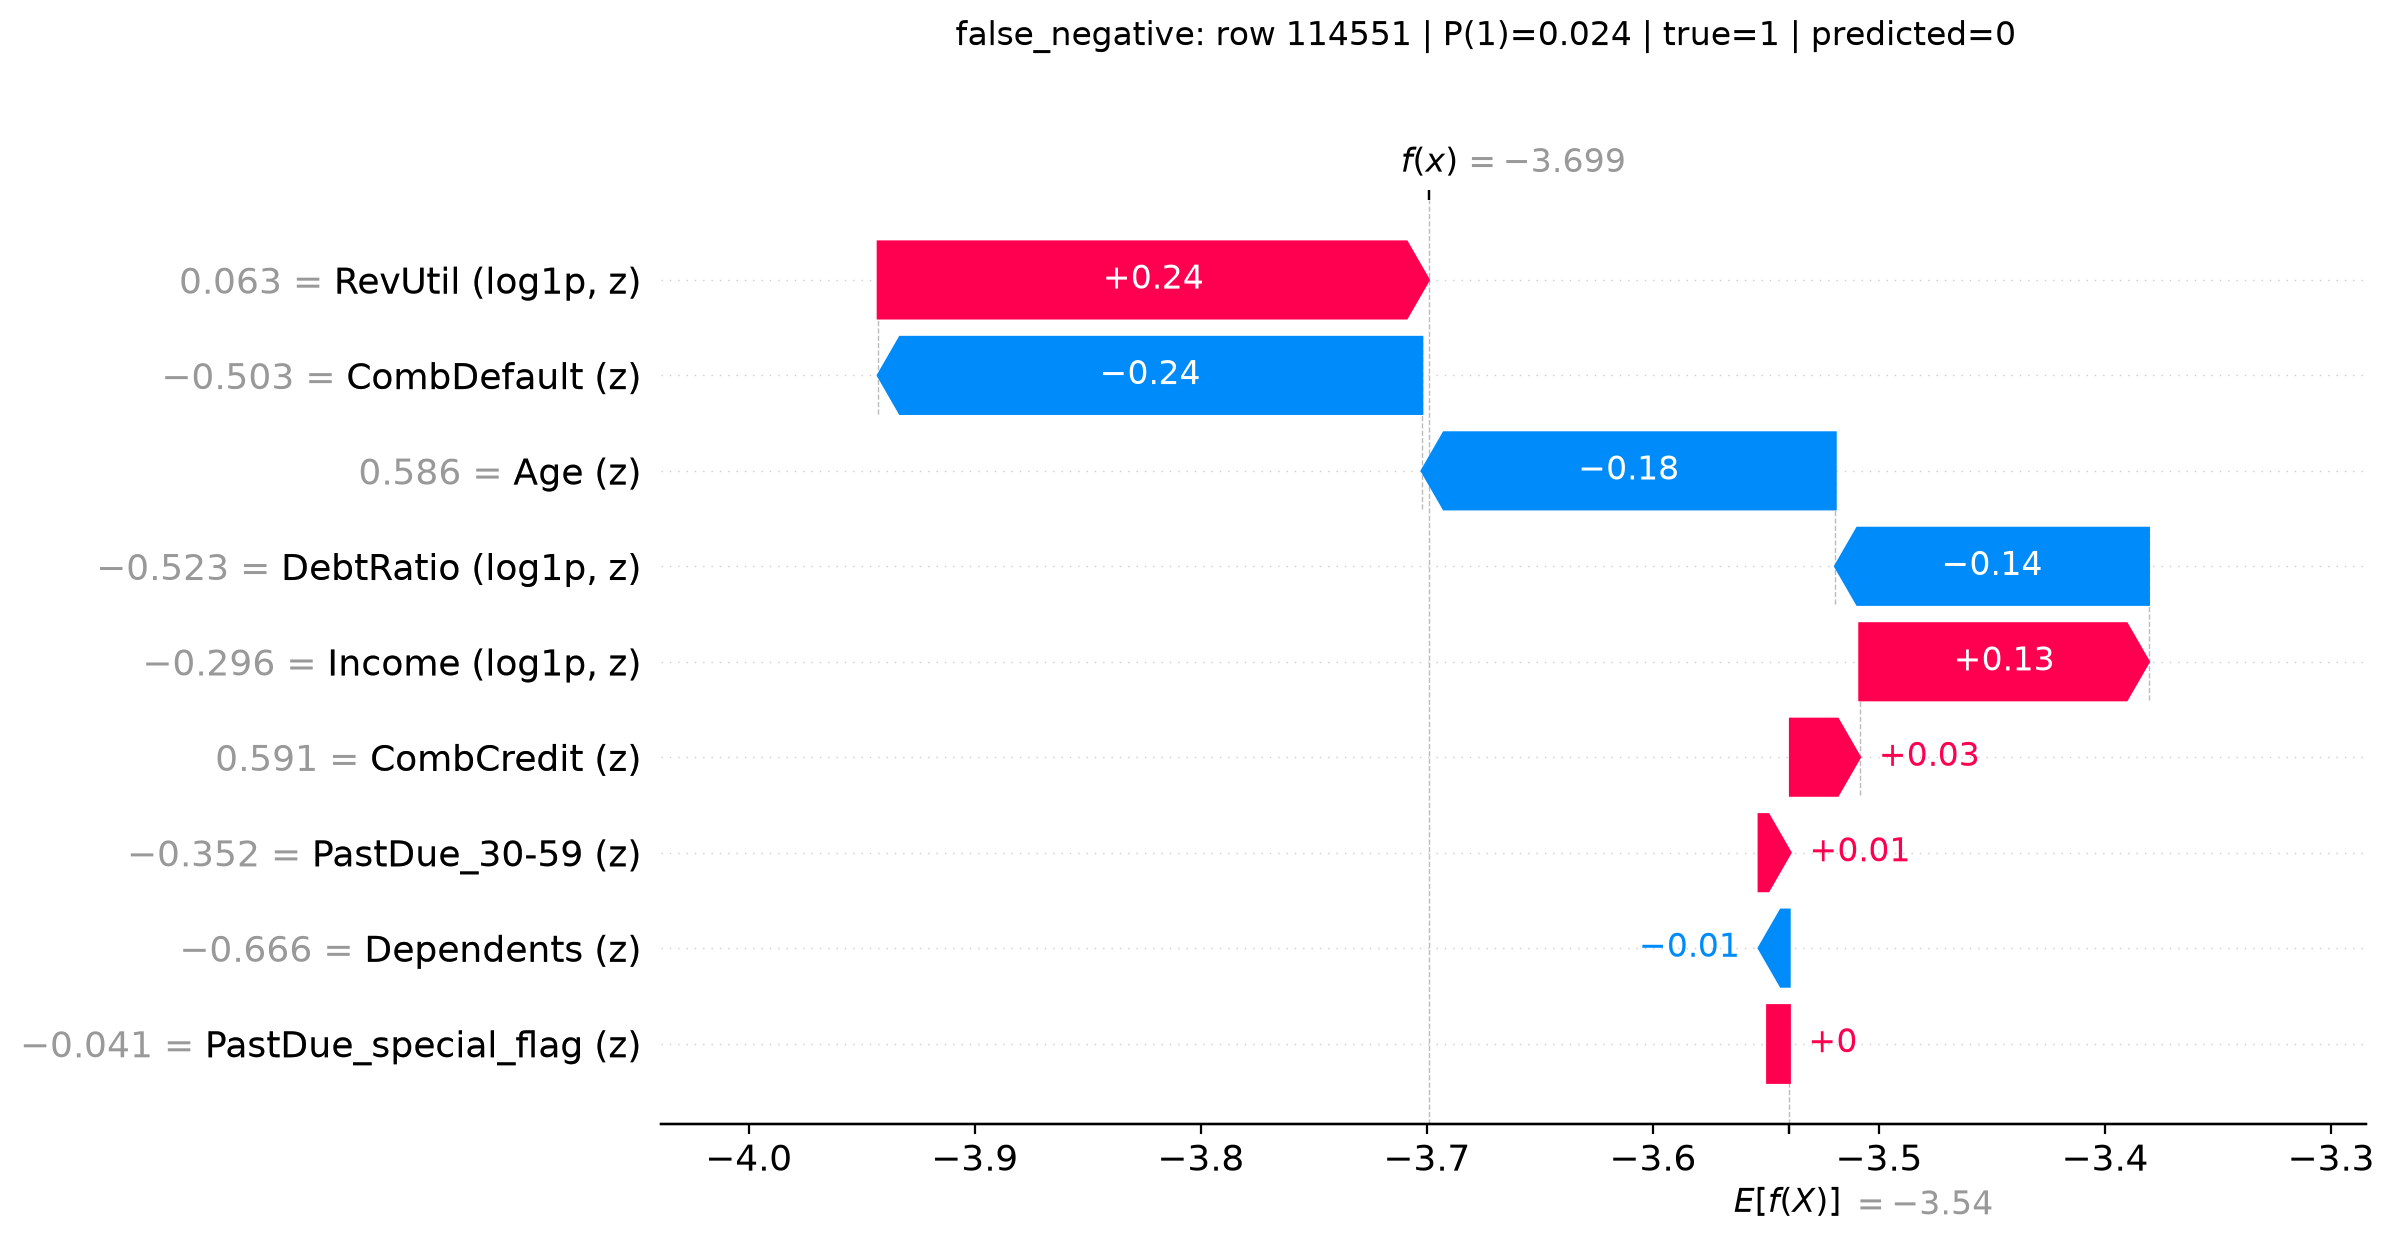

In [30]:
from IPython.display import Image, display

display(pd.read_csv("submission/xai/global_importance.csv"))
display(Image(filename="submission/xai/global_importance.png"))
display(Image(filename="submission/xai/beeswarm.png"))
display(Image(filename="submission/xai/top_feature_dependence.png"))

# 실제 라벨·확률·고정 임계값·원 단위 입력을 함께 보고 모델 오류도 확인한다.
display(pd.read_csv("submission/xai/local_cases.csv"))
for case in ["high_risk", "low_risk", "false_positive", "false_negative"]:
    display(Image(filename=f"submission/xai/waterfall_{case}.png"))
